In [102]:
import os
import librosa
import numpy as np
import time
import joblib
from sklearn.metrics import accuracy_score
import librosa.display
import scipy.fftpack as fftpack
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt


In [103]:
# Helper: plot and save confusion matrix + print accuracy
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

def report_confusion(y_true, y_pred, title, folder="confusion_matrices"):
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=np.unique(y_true))
    disp = ConfusionMatrixDisplay(cm, display_labels=np.unique(y_true))
    plt.figure(figsize=(5,4))
    disp.plot(cmap="Blues", colorbar=False)
    safe_name = "".join(c for c in title if c.isalnum() or c in " _-_").strip().replace(" ", "_")
    os.makedirs(folder, exist_ok=True)
    save_path = os.path.join(folder, f"{safe_name}.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{title} - Accuracy: {acc*100:.2f}%")
    print(f"Saved: {save_path}")
    return acc

In [104]:
train_path = 'D:/Queenless/archive/nuhive_processed/train'
val_path = 'D:/Queenless/archive/nuhive_processed/val'
test_path = 'D:/Queenless/archive/nuhive_processed/test'

output_dir = 'D:/Queenless/kaggle_features'
os.makedirs(output_dir, exist_ok=True)

# FFT (origin)

In [105]:
from sklearn.preprocessing import LabelEncoder

def extract_fft_features(file_path, n_fft=2048):
    """Extract FFT features from audio file"""
    try:
        # Load audio file
        audio, sr = librosa.load(file_path, sr=None)
        
        # Compute FFT
        fft = np.fft.fft(audio, n=n_fft)
        fft_magnitude = np.abs(fft[:n_fft//2])  # Take only positive frequencies
        
        return fft_magnitude
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def load_dataset_fft():
    base_path = r"D:\Queenless\archive\nuhive_processed"
    
    # Initialize lists
    train_features_fft, train_labels_fft = [], []
    val_features_fft, val_labels_fft = [], []
    test_features_fft, test_labels_fft = [], []
    
    # Process each split
    for split in ['train', 'val', 'test']:
        for label in ['bee', 'nobee', 'noqueen']:
            folder_path = os.path.join(base_path, split, label)
            
            if os.path.exists(folder_path):
                for file_name in os.listdir(folder_path):
                    if file_name.endswith('.wav'):
                        file_path = os.path.join(folder_path, file_name)
                        features = extract_fft_features(file_path)
                        
                        if features is not None:
                            if split == 'train':
                                train_features_fft.append(features)
                                train_labels_fft.append(label)
                            elif split == 'val':
                                val_features_fft.append(features)
                                val_labels_fft.append(label)
                            elif split == 'test':
                                test_features_fft.append(features)
                                test_labels_fft.append(label)
    
    # Convert to numpy arrays
    train_features_fft = np.array(train_features_fft)
    val_features_fft = np.array(val_features_fft)
    test_features_fft = np.array(test_features_fft)
    
    # Encode labels
    le = LabelEncoder()
    all_labels = train_labels_fft + val_labels_fft + test_labels_fft
    le.fit(all_labels)
    
    train_labels_fft = le.transform(train_labels_fft)
    val_labels_fft = le.transform(val_labels_fft)
    test_labels_fft = le.transform(test_labels_fft)
    
    print(f"Train: {train_features_fft.shape}, Val: {val_features_fft.shape}, Test: {test_features_fft.shape}")
    
    return (train_features_fft, train_labels_fft, 
            val_features_fft, val_labels_fft, 
            test_features_fft, test_labels_fft)

# Load dataset
train_features_fft, train_labels_fft, val_features_fft, val_labels_fft, test_features_fft, test_labels_fft = load_dataset_fft()

train_features_fft = np.vstack((train_features_fft, val_features_fft))
train_labels_fft = np.hstack((train_labels_fft, val_labels_fft))

Train: (9653, 1024), Val: (1379, 1024), Test: (2760, 1024)


In [106]:
scaler = StandardScaler()
train_features_fft_scaled = scaler.fit_transform(train_features_fft)
test_features_fft_scaled = scaler.transform(test_features_fft)

Training time: 0.02 seconds


<Figure size 500x400 with 0 Axes>

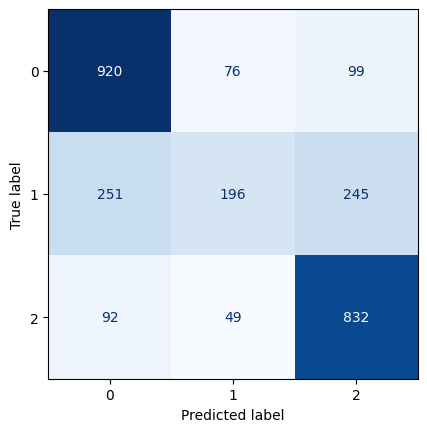

KNN (FFT features) - Accuracy: 70.58%
Saved: confusion_matrices\KNN_FFT_features.png


0.7057971014492753

In [107]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=19)
knn_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_fft_knn = knn_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_accuracy_fft_knn, "KNN (FFT features)")

Training time: 0.01 seconds


<Figure size 500x400 with 0 Axes>

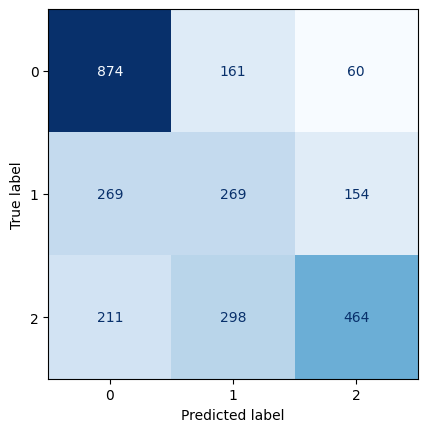

KNN (FFT features scaled) - Accuracy: 58.22%
Saved: confusion_matrices\KNN_FFT_features_scaled.png


0.5822463768115942

In [108]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=19)
knn_classifier.fit(train_features_fft_scaled, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_fft_knn = knn_classifier.predict(test_features_fft_scaled)
report_confusion(test_labels_fft, test_accuracy_fft_knn, "KNN (FFT features scaled)")

Training time: 41.29 seconds


<Figure size 500x400 with 0 Axes>

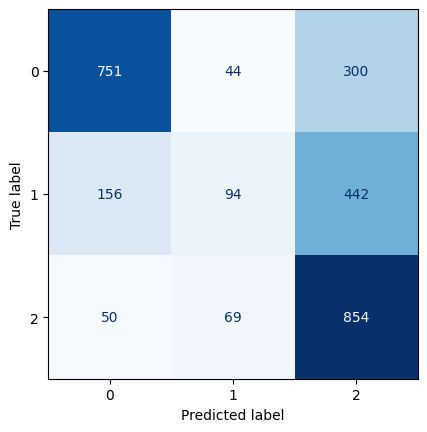

SVM RBF (FFT features) - Accuracy: 61.56%
Saved: confusion_matrices\SVM_RBF_FFT_features.png


0.6155797101449275

In [109]:
start_time = time.time()

svm_rbf_classifier = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

# Huấn luyện mô hình SVM
svm_rbf_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_predictions_svm_rbf, "SVM RBF (FFT features)")

Training time: 64.66 seconds


<Figure size 500x400 with 0 Axes>

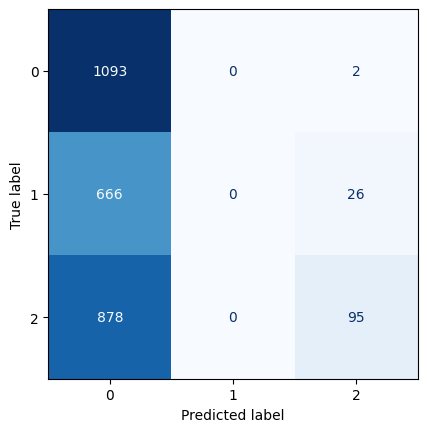

SVM RBF (FFT features scaled) - Accuracy: 43.04%
Saved: confusion_matrices\SVM_RBF_FFT_features_scaled.png


0.43043478260869567

In [110]:
start_time = time.time()

svm_rbf_classifier = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

# Huấn luyện mô hình SVM
svm_rbf_classifier.fit(train_features_fft_scaled, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(test_features_fft_scaled)
report_confusion(test_labels_fft, test_predictions_svm_rbf, "SVM RBF (FFT features scaled)")

Training time: 36.79 seconds


<Figure size 500x400 with 0 Axes>

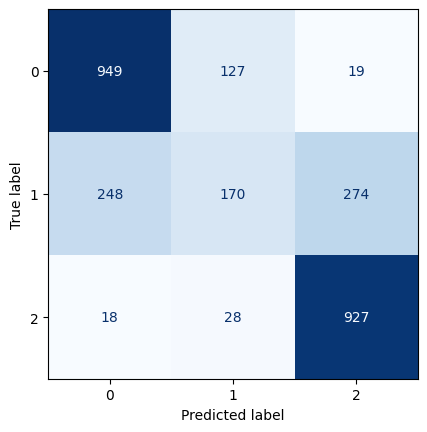

Random Forest (FFT features) - Accuracy: 74.13%
Saved: confusion_matrices\Random_Forest_FFT_features.png


0.741304347826087

In [111]:
start_time = time.time()

rf_classifier = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                       min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                       max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                       n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                       ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_fft_rf = rf_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_accuracy_fft_rf, "Random Forest (FFT features)")

Training time: 8.01 seconds


<Figure size 500x400 with 0 Axes>

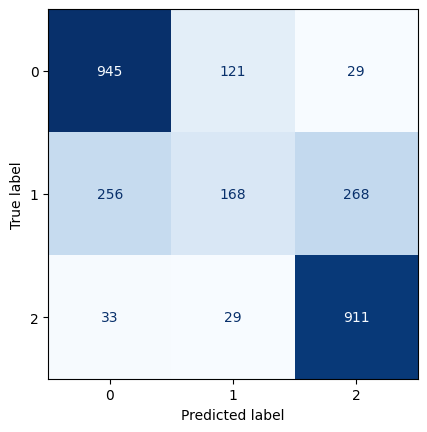

Extra Trees (FFT features) - Accuracy: 73.33%
Saved: confusion_matrices\Extra_Trees_FFT_features.png


0.7333333333333333

In [112]:
start_time = time.time()

et_classifier = ExtraTreesClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=False,
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None,
                                     ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

et_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_fft_et = et_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_accuracy_fft_et, "Extra Trees (FFT features)")

# FFTs (with pre-emphasis, framing, windowing)

In [113]:
def pre_emphasis(signal_in, pre_emph=0.97):
    """
    Áp dụng pre-emphasis để nhấn mạnh các tần số cao.
    """
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01):
    """
    Chia tín hiệu thành các frame có kích thước và bước nhảy xác định.
    """
    frame_length = int(round(frame_size * sample_rate))
    frame_step = int(round(frame_stride * sample_rate))
    signal_length = len(signal_in)
    num_frames = int(np.ceil(np.abs(signal_length - frame_length) / frame_step)) + 1

    pad_signal_length = num_frames * frame_step + frame_length
    z = np.zeros((pad_signal_length - signal_length))
    pad_signal = np.append(signal_in, z)

    indices = np.tile(np.arange(0, frame_length), (num_frames, 1)) + \
              np.tile(np.arange(0, num_frames * frame_step, frame_step), (frame_length, 1)).T
    frames = pad_signal[indices.astype(np.int32, copy=False)]
    return frames

def windowing(frames):
    """
    Áp dụng cửa sổ Hamming cho mỗi frame.
    """
    frame_length = frames.shape[1]
    hamming = np.hamming(frame_length)
    return frames * hamming

def fft_frames(frames, NFFT=512):
    """
    Tính FFT cho mỗi frame và lấy giá trị magnitude.
    """
    return np.absolute(np.fft.rfft(frames, NFFT))

def compute_fft_features(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01, NFFT=512, apply_log=True):
    """
    Tính toán đặc trưng FFT cho tín hiệu âm thanh:
      - Pre-emphasis, Framing, Windowing.
      - Tính FFT cho từng frame và lấy giá trị magnitude.
      - Trung bình các frame để có vector đặc trưng ổn định.
      - (Tùy chọn) Áp dụng log để giảm phạm vi giá trị.
      
    Trả về: vector đặc trưng có kích thước (NFFT/2+1,).
    """
    emphasized_signal = pre_emphasis(signal_in)
    frames = framing(emphasized_signal, sample_rate, frame_size, frame_stride)
    windowed_frames = windowing(frames)
    mag_frames = fft_frames(windowed_frames, NFFT)
    fft_feature = np.mean(mag_frames, axis=0)  # Trung bình theo các frame
    if apply_log:
        fft_feature = np.log(fft_feature + 1e-8)  # Thêm epsilon để tránh log(0)
    return fft_feature


In [114]:
def load_fft_features_from_directory(directory, sample_rate=22050, NFFT=512, output_dir=None, dataset_type='train'):
    """
    Duyệt qua các file âm thanh trong thư mục và tính đặc trưng FFT cho mỗi file.
    Giả sử trong directory có hai thư mục con: 'Queen' và 'NonQueen'.
    
    Trả về:
      - features: mảng đặc trưng (mỗi đặc trưng có kích thước NFFT/2+1)
      - labels: nhãn tương ứng.
    """
    # Kiểm tra nếu file đã tồn tại, thì load lại
    features_file = os.path.join(output_dir, f'fft3_features_{dataset_type}.pkl')
    labels_file = os.path.join(output_dir, f'fft3_labels_{dataset_type}.pkl')
    
    if os.path.exists(features_file) and os.path.exists(labels_file):
        print(f"Loading {dataset_type} data from .pkl files...")
        features = joblib.load(features_file)
        labels = joblib.load(labels_file)
    else:
        print(f"Extracting {dataset_type} data...")
        start_time = time.time()
        labels = []
        features = []
        
        for label in ['bee', 'nobee', 'noqueen']:
            path = os.path.join(directory, label)
            for file in os.listdir(path):
                file_path = os.path.join(path, file)
                signal, sr = librosa.load(file_path, sr=sample_rate)
                fft_feature = compute_fft_features(signal, sr, NFFT=NFFT)
                features.append(fft_feature)
                labels.append(label)
        
        features = np.array(features)
        labels = np.array(labels)
        
        # Lưu dữ liệu vào file .pkl nếu chưa tồn tại
        if output_dir:
            joblib.dump(features, features_file)
            joblib.dump(labels, labels_file)
        
        end_time = time.time()
        print(f"FFT extraction time: {end_time - start_time:.2f} seconds")
    
    return features, labels

In [115]:
train_features_fft, train_labels_fft = load_fft_features_from_directory(train_path, sample_rate=22050, NFFT=512, output_dir=output_dir, dataset_type='train')
val_features_fft, val_labels_fft = load_fft_features_from_directory(val_path, sample_rate=22050, NFFT=512, output_dir=output_dir, dataset_type='val')
test_features_fft, test_labels_fft = load_fft_features_from_directory(test_path, sample_rate=22050, NFFT=512, output_dir=output_dir, dataset_type='test')

train_features_fft = np.vstack((train_features_fft, val_features_fft))
train_labels_fft = np.hstack((train_labels_fft, val_labels_fft))

Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...


In [116]:
train_features_fft.shape

(11032, 257)

In [117]:
scaler = StandardScaler()
train_features_fft_scaled = scaler.fit_transform(train_features_fft)
test_features_fft_scaled = scaler.transform(test_features_fft)

FFTs - KNN

Training time: 0.01 seconds


<Figure size 500x400 with 0 Axes>

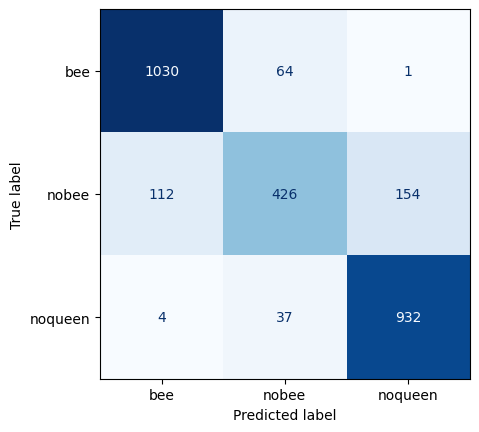

KNN (FFTs features preprocessed) - Accuracy: 86.52%
Saved: confusion_matrices\KNN_FFTs_features_preprocessed.png


0.8652173913043478

In [118]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_fft_knn = knn_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_accuracy_fft_knn, "KNN (FFTs features preprocessed)")

Training time: 0.01 seconds


<Figure size 500x400 with 0 Axes>

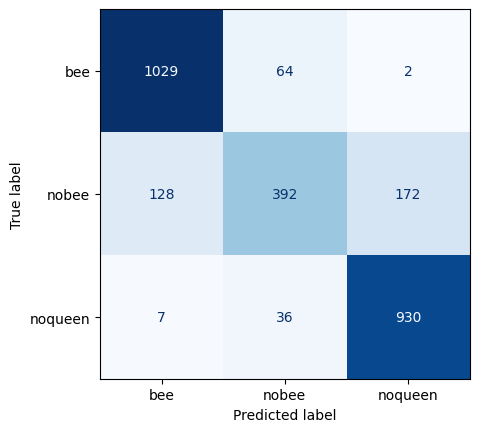

KNN (FFTs features preprocessed scaled) - Accuracy: 85.18%
Saved: confusion_matrices\KNN_FFTs_features_preprocessed_scaled.png


0.8518115942028985

In [119]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features_fft_scaled, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_fft_knn = knn_classifier.predict(test_features_fft_scaled)
report_confusion(test_labels_fft, test_accuracy_fft_knn, "KNN (FFTs features preprocessed scaled)")

FFTs - SVM

Training time: 3.58 seconds


<Figure size 500x400 with 0 Axes>

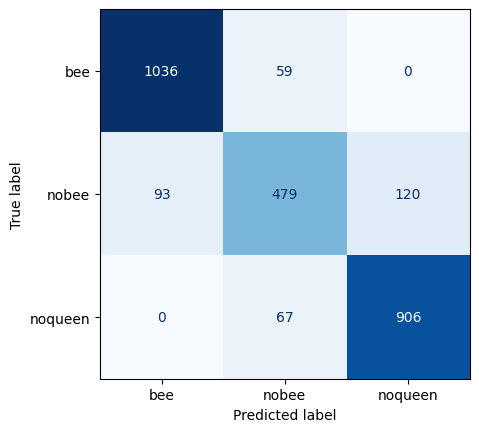

SVM RBF (FFTs features) - Accuracy: 87.72%
Saved: confusion_matrices\SVM_RBF_FFTs_features.png


0.8771739130434782

In [120]:
start_time = time.time()

svm_rbf_classifier = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

# Huấn luyện mô hình SVM
svm_rbf_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_predictions_svm_rbf, "SVM RBF (FFTs features)")

97.47%

Training time: 4.39 seconds


<Figure size 500x400 with 0 Axes>

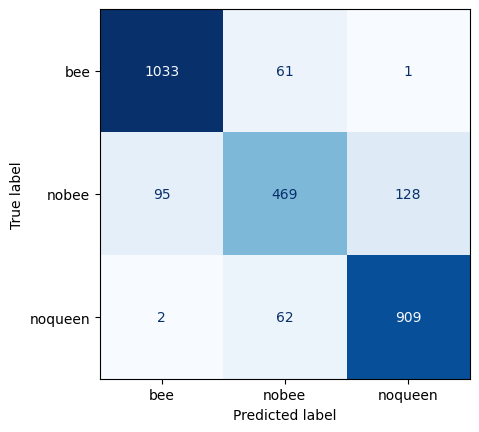

SVM RBF (FFTs features scaled) - Accuracy: 87.36%
Saved: confusion_matrices\SVM_RBF_FFTs_features_scaled.png


0.8735507246376811

In [121]:
start_time = time.time()

svm_rbf_classifier = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

# Huấn luyện mô hình SVM
svm_rbf_classifier.fit(train_features_fft_scaled, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(test_features_fft_scaled)
report_confusion(test_labels_fft, test_predictions_svm_rbf, "SVM RBF (FFTs features scaled)")

97.82

FFTs - RF

Training time: 15.11 seconds


<Figure size 500x400 with 0 Axes>

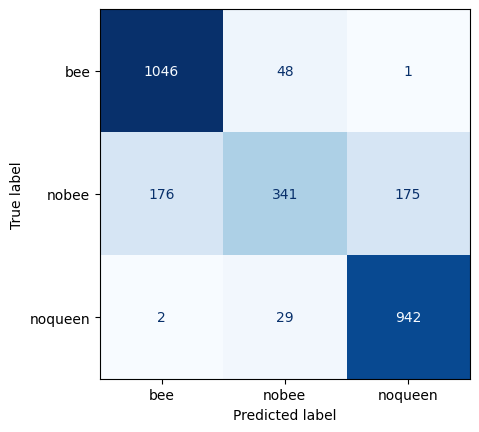

Random Forest (FFTs features) - Accuracy: 84.38%
Saved: confusion_matrices\Random_Forest_FFTs_features.png


0.8438405797101449

In [122]:
start_time = time.time()

rf_classifier = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                       min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                       max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                       n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                       ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_fft_rf = rf_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_accuracy_fft_rf, "Random Forest (FFTs features)")

Not tuning yet

FFTs - ET

Training time: 44.80 seconds


<Figure size 500x400 with 0 Axes>

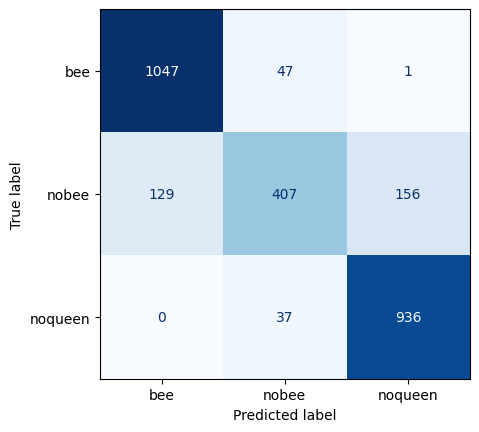

Extra Trees (FFTs features) - Accuracy: 86.59%
Saved: confusion_matrices\Extra_Trees_FFTs_features.png


0.8659420289855072

In [123]:
start_time = time.time()

et_classifier = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

# Huấn luyện mô hình Extra Trees với dữ liệu đã chuẩn hóa
et_classifier.fit(train_features_fft, train_labels_fft)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_et = et_classifier.predict(test_features_fft)
report_confusion(test_labels_fft, test_predictions_et, "Extra Trees (FFTs features)")

93.95% -> 95.80% beautifull

# STFT

In [124]:
import numpy as np
import librosa

def compute_stft_features(signal_in, sample_rate, n_fft=2048, hop_length=512, apply_log=True):
    """
    Tính đặc trưng STFT của tín hiệu:
      - Tính STFT bằng librosa.stft và lấy giá trị magnitude.
      - (Tùy chọn) Áp dụng log scaling.
      - Trung bình theo trục thời gian (axis=1) để thu được vector đặc trưng có kích thước (n_fft/2+1,).
    """
    stft_matrix = np.abs(librosa.stft(signal_in, n_fft=n_fft, hop_length=hop_length))
    if apply_log:
        stft_matrix = np.log(stft_matrix + 1e-8)  # Thêm epsilon để tránh log(0)
    # Trung bình theo trục thời gian (tính trung bình các cột)
    features = np.mean(stft_matrix, axis=1)
    return features

In [125]:
def load_stft_features_from_directory(directory, sample_rate=22050, n_fft=2048, hop_length=512, output_dir=None, dataset_type='train'):
    """
    Load and compute stft features from audio files in a directory, with improved accuracy.
    Assumes 'Queen' and 'NonQueen' subdirectories are present.
    """
    # Kiểm tra nếu file đã tồn tại, thì load lại
    features_file = os.path.join(output_dir, f'stft2_features_{dataset_type}.pkl')
    labels_file = os.path.join(output_dir, f'stft2_labels_{dataset_type}.pkl')
    
    if os.path.exists(features_file) and os.path.exists(labels_file):
        print(f"Loading {dataset_type} data from .pkl files...")
        features = joblib.load(features_file)
        labels = joblib.load(labels_file)
    else:
        print(f"Extracting {dataset_type} data...")
        start_time = time.time()
        labels = []
        features = []

        for label in ['bee', 'nobee', 'noqueen']:
            path = os.path.join(directory, label)
            for file in os.listdir(path):
                file_path = os.path.join(path, file)
                # Load audio file
                signal, sr = librosa.load(file_path, sr=sample_rate)

                # Compute stft features
                stft_feature = compute_stft_features(signal, sr, n_fft=n_fft, hop_length=hop_length, apply_log=True)

                features.append(stft_feature)
                labels.append(label)

        features = np.array(features)
        labels = np.array(labels)

        # Lưu dữ liệu vào file .pkl nếu chưa tồn tại
        if output_dir:
            joblib.dump(features, features_file)
            joblib.dump(labels, labels_file)

        end_time = time.time()
        print(f"stft extraction time: {end_time - start_time:.2f} seconds")
    
    return features, labels

train_features_stft, train_labels_stft = load_stft_features_from_directory(train_path, sample_rate=22050, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='train')
val_features_stft, val_labels_stft = load_stft_features_from_directory(val_path, sample_rate=22050, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='val')
test_features_stft, test_labels_stft = load_stft_features_from_directory(test_path, sample_rate=22050, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='test')

train_features_stft = np.vstack((train_features_stft, val_features_stft))
train_labels_stft = np.hstack((train_labels_stft, val_labels_stft))

Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...


In [126]:
scaler_stft = StandardScaler()
train_features_stft_scaled = scaler_stft.fit_transform(train_features_stft)
test_features_stft_scaled  = scaler_stft.transform(test_features_stft)

In [127]:
train_features_stft_scaled.shape

(11032, 2049)

<Figure size 500x400 with 0 Axes>

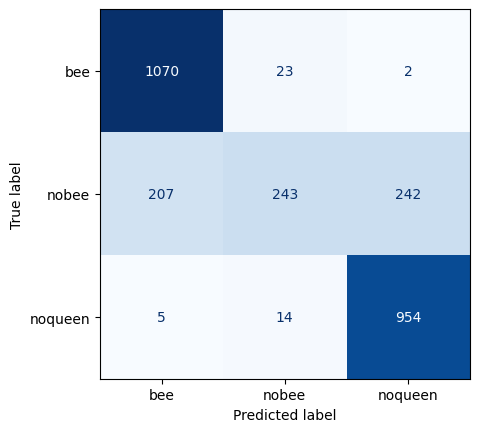

KNN (STFT features) - Accuracy: 82.14%
Saved: confusion_matrices\KNN_STFT_features.png


0.821376811594203

In [128]:
knn_classifier_stft = KNeighborsClassifier(n_neighbors=25)
knn_classifier_stft.fit(train_features_stft_scaled, train_labels_stft)
test_pred_stft_knn = knn_classifier_stft.predict(test_features_stft_scaled)

report_confusion(test_labels_stft, test_pred_stft_knn, "KNN (STFT features)")

<Figure size 500x400 with 0 Axes>

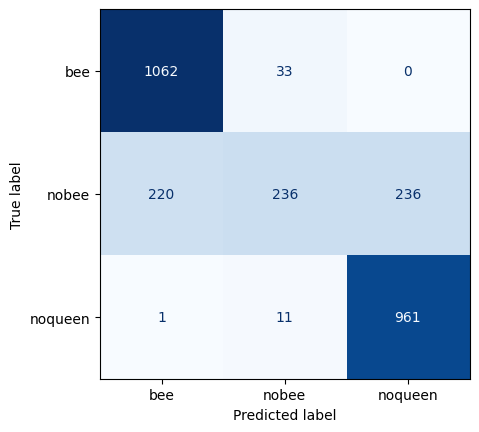

SVM RBF (STFT features) - Accuracy: 81.85%
Saved: confusion_matrices\SVM_RBF_STFT_features.png


0.8184782608695652

In [129]:
# Khởi tạo mô hình SVM với data scaling
svm_rbf_classifier = SVC(C=10, kernel='rbf', degree=3, gamma='scale', coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

# Huấn luyện mô hình SVM
svm_rbf_classifier.fit(train_features_stft, train_labels_stft)

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(test_features_stft)
report_confusion(test_labels_stft, test_predictions_svm_rbf, "SVM RBF (STFT features)")

Test Accuracy (SVM with RBF Kernel): 82.32%


<Figure size 500x400 with 0 Axes>

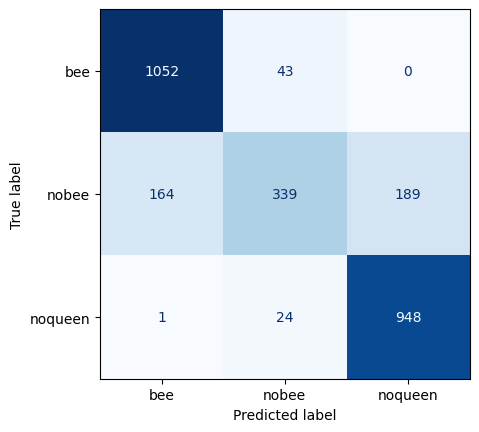

SVM RBF (STFT features scaled) - Accuracy: 84.75%
Saved: confusion_matrices\SVM_RBF_STFT_features_scaled.png


0.847463768115942

In [130]:
# Khởi tạo mô hình SVM với data scaling
svm_rbf_classifier = SVC(C=10, kernel='rbf', degree=3, gamma='scale', coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

# Huấn luyện mô hình SVM
svm_rbf_classifier.fit(train_features_stft_scaled, train_labels_stft)

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(test_features_stft_scaled)
report_confusion(test_labels_stft, test_predictions_svm_rbf, "SVM RBF (STFT features scaled)")

<Figure size 500x400 with 0 Axes>

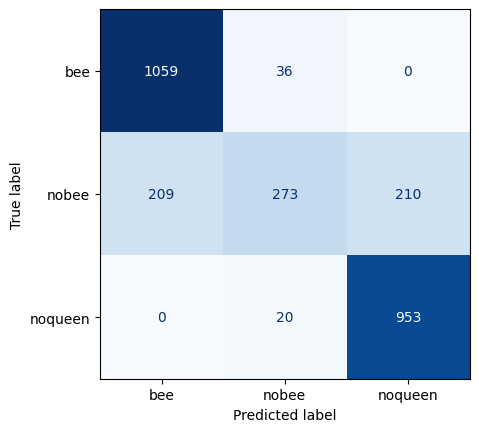

Random Forest (STFT features) - Accuracy: 82.79%
Saved: confusion_matrices\Random_Forest_STFT_features.png


0.8278985507246377

In [131]:
rf_classifier_stft = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier_stft.fit(train_features_stft, train_labels_stft)

test_pred_stft_rf = rf_classifier_stft.predict(test_features_stft)

report_confusion(test_labels_stft, test_pred_stft_rf, "Random Forest (STFT features)")

<Figure size 500x400 with 0 Axes>

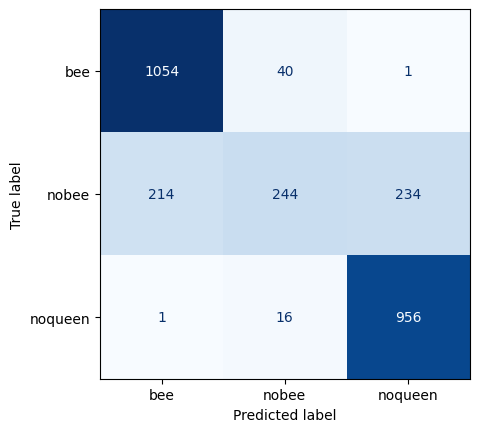

Extra Trees (STFT features) - Accuracy: 81.67%
Saved: confusion_matrices\Extra_Trees_STFT_features.png


0.8166666666666667

In [132]:
from sklearn.ensemble import ExtraTreesClassifier

et_classifier_stft = ExtraTreesClassifier(n_estimators=100, random_state=42)
et_classifier_stft.fit(train_features_stft_scaled, train_labels_stft)

test_pred_stft_et = et_classifier_stft.predict(test_features_stft_scaled)

report_confusion(test_labels_stft, test_pred_stft_et, "Extra Trees (STFT features)")

# FFTs + STFT

In [133]:
# Kết hợp FFTs + STFT (không phải STFTs)
# Kiểm tra kích thước và tính nhất quán của nhãn
print(f"FFTs train features shape: {train_features_fft.shape}")
print(f"STFT train features shape: {train_features_stft.shape}")
print(f"FFTs test features shape: {test_features_fft.shape}")
print(f"STFT test features shape: {test_features_stft.shape}")

if np.array_equal(train_labels_fft, train_labels_stft) and np.array_equal(test_labels_fft, test_labels_stft):
    print("\u2713 Labels are consistent between FFTs and STFT")
    combined_train_labels_ffts_stft = train_labels_fft
    combined_test_labels_ffts_stft = test_labels_fft
else:
    print("\u26a0 Warning: Labels are not consistent, using FFTs labels")
    combined_train_labels_ffts_stft = train_labels_fft
    combined_test_labels_ffts_stft = test_labels_fft

# Nối đặc trưng FFTs và STFT
combined_train_features_ffts_stft = np.hstack((train_features_fft, train_features_stft))
combined_test_features_ffts_stft = np.hstack((test_features_fft, test_features_stft))

print(f"\nCombined FFTs+STFT train features shape: {combined_train_features_ffts_stft.shape}")
print(f"Combined FFTs+STFT test features shape: {combined_test_features_ffts_stft.shape}")

# Chuẩn hóa dữ liệu
scaler_ffts_stft = StandardScaler()
combined_train_features_ffts_stft_scaled = scaler_ffts_stft.fit_transform(combined_train_features_ffts_stft)
combined_test_features_ffts_stft_scaled = scaler_ffts_stft.transform(combined_test_features_ffts_stft)

print("Feature combination (FFTs + STFT) completed!")




FFTs train features shape: (11032, 257)
STFT train features shape: (11032, 2049)
FFTs test features shape: (2760, 257)
STFT test features shape: (2760, 2049)
✓ Labels are consistent between FFTs and STFT

Combined FFTs+STFT train features shape: (11032, 2306)
Combined FFTs+STFT test features shape: (2760, 2306)
Feature combination (FFTs + STFT) completed!


Training time (KNN raw): 0.04 seconds


<Figure size 500x400 with 0 Axes>

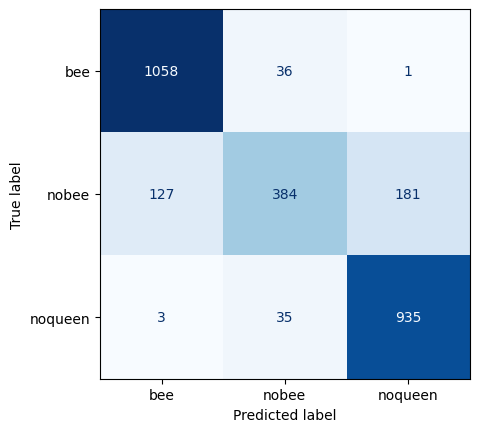

KNN (FFTs+STFT features) - Accuracy: 86.12%
Saved: confusion_matrices\KNN_FFTsSTFT_features.png
Training time (KNN scaled): 0.03 seconds


<Figure size 500x400 with 0 Axes>

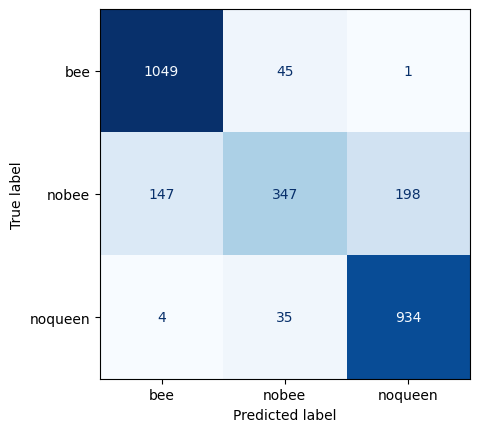

KNN (FFTs+STFT features scaled) - Accuracy: 84.42%
Saved: confusion_matrices\KNN_FFTsSTFT_features_scaled.png


0.8442028985507246

In [134]:
# FFTs + STFT - KNN (raw)
start_time = time.time()
knn_classifier_ffts_stft = KNeighborsClassifier(n_neighbors=5)
knn_classifier_ffts_stft.fit(combined_train_features_ffts_stft, combined_train_labels_ffts_stft)
print(f"Training time (KNN raw): {time.time() - start_time:.2f} seconds")

pred_knn_ffts_stft = knn_classifier_ffts_stft.predict(combined_test_features_ffts_stft)
report_confusion(combined_test_labels_ffts_stft, pred_knn_ffts_stft, "KNN (FFTs+STFT features)")

# FFTs + STFT - KNN (scaled)
start_time = time.time()
knn_classifier_ffts_stft_scaled = KNeighborsClassifier(n_neighbors=5)
knn_classifier_ffts_stft_scaled.fit(combined_train_features_ffts_stft_scaled, combined_train_labels_ffts_stft)
print(f"Training time (KNN scaled): {time.time() - start_time:.2f} seconds")

pred_knn_ffts_stft_scaled = knn_classifier_ffts_stft_scaled.predict(combined_test_features_ffts_stft_scaled)
report_confusion(combined_test_labels_ffts_stft, pred_knn_ffts_stft_scaled, "KNN (FFTs+STFT features scaled)")

Training time (SVM raw): 187.58 seconds


<Figure size 500x400 with 0 Axes>

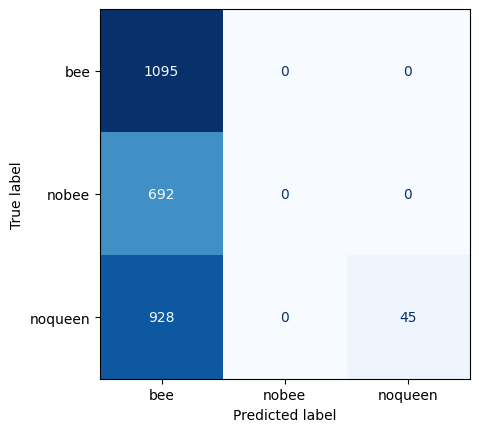

SVM RBF (FFTs+STFT features) - Accuracy: 41.30%
Saved: confusion_matrices\SVM_RBF_FFTsSTFT_features.png
Training time (SVM scaled): 204.10 seconds


<Figure size 500x400 with 0 Axes>

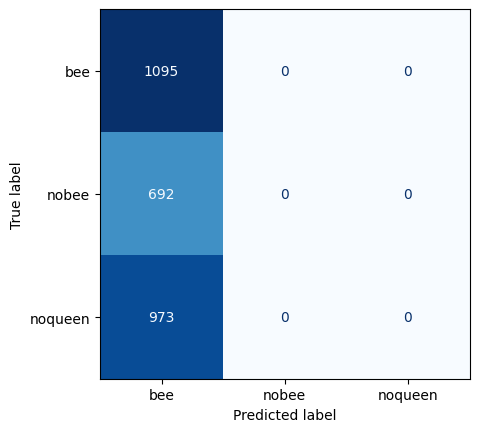

SVM RBF (FFTs+STFT features scaled) - Accuracy: 39.67%
Saved: confusion_matrices\SVM_RBF_FFTsSTFT_features_scaled.png


0.3967391304347826

In [135]:
# FFTs + STFT - SVM (raw)
start_time = time.time()
svm_rbf_ffts_stft = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                        probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                        max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)
svm_rbf_ffts_stft.fit(combined_train_features_ffts_stft, combined_train_labels_ffts_stft)
print(f"Training time (SVM raw): {time.time() - start_time:.2f} seconds")

pred_svm_ffts_stft = svm_rbf_ffts_stft.predict(combined_test_features_ffts_stft)
report_confusion(combined_test_labels_ffts_stft, pred_svm_ffts_stft, "SVM RBF (FFTs+STFT features)")

# FFTs + STFT - SVM (scaled)
start_time = time.time()
svm_rbf_ffts_stft_scaled = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                               probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                               max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)
svm_rbf_ffts_stft_scaled.fit(combined_train_features_ffts_stft_scaled, combined_train_labels_ffts_stft)
print(f"Training time (SVM scaled): {time.time() - start_time:.2f} seconds")

pred_svm_ffts_stft_scaled = svm_rbf_ffts_stft_scaled.predict(combined_test_features_ffts_stft_scaled)
report_confusion(combined_test_labels_ffts_stft, pred_svm_ffts_stft_scaled, "SVM RBF (FFTs+STFT features scaled)")

Training time (RF): 51.83 seconds


<Figure size 500x400 with 0 Axes>

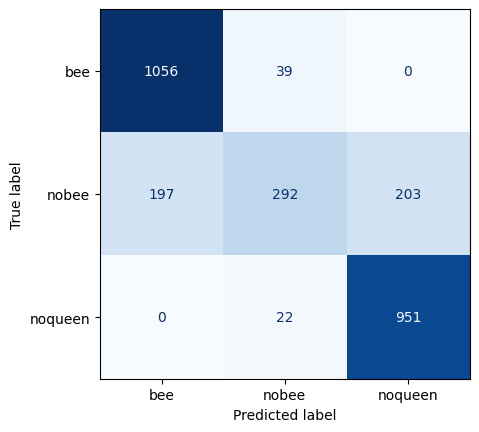

Random Forest (FFTs+STFT features) - Accuracy: 83.30%
Saved: confusion_matrices\Random_Forest_FFTsSTFT_features.png


0.8329710144927536

In [136]:
# FFTs + STFT - RF
start_time = time.time()
rf_ffts_stft = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                     ccp_alpha=0.0, max_samples=None, monotonic_cst=None)
rf_ffts_stft.fit(combined_train_features_ffts_stft, combined_train_labels_ffts_stft)
print(f"Training time (RF): {time.time() - start_time:.2f} seconds")

pred_rf_ffts_stft = rf_ffts_stft.predict(combined_test_features_ffts_stft)
report_confusion(combined_test_labels_ffts_stft, pred_rf_ffts_stft, "Random Forest (FFTs+STFT features)")

Training time (ET): 531.28 seconds


<Figure size 500x400 with 0 Axes>

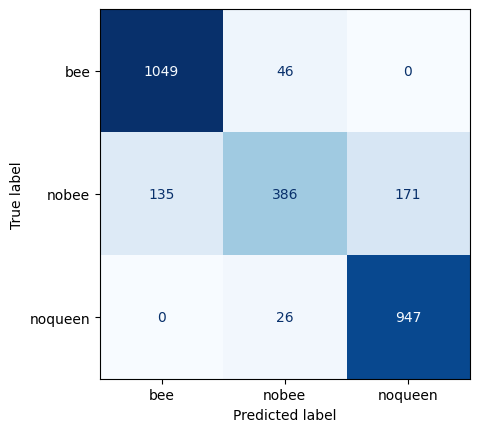

Extra Trees (FFTs+STFT features) - Accuracy: 86.30%
Saved: confusion_matrices\Extra_Trees_FFTsSTFT_features.png


0.8630434782608696

In [137]:

# FFTs + STFT - ET
start_time = time.time()
et_ffts_stft = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                   min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                   bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                   class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)
et_ffts_stft.fit(combined_train_features_ffts_stft, combined_train_labels_ffts_stft)
print(f"Training time (ET): {time.time() - start_time:.2f} seconds")

pred_et_ffts_stft = et_ffts_stft.predict(combined_test_features_ffts_stft)
report_confusion(combined_test_labels_ffts_stft, pred_et_ffts_stft, "Extra Trees (FFTs+STFT features)")

# STFTs

In [138]:
import numpy as np
import librosa

def pre_emphasis(signal_in, pre_emph=0.97):
    """
    Áp dụng pre-emphasis để nhấn mạnh các tần số cao.
    """
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01):
    """
    Chia tín hiệu thành các frame có kích thước và bước nhảy xác định.
    """
    frame_length = int(round(frame_size * sample_rate))
    frame_step = int(round(frame_stride * sample_rate))
    signal_length = len(signal_in)
    
    num_frames = int(np.ceil(float(np.abs(signal_length - frame_length)) / frame_step)) + 1

    pad_signal_length = num_frames * frame_step + frame_length
    pad_signal = np.pad(signal_in, (0, pad_signal_length - signal_length), mode='constant')

    indices = np.arange(0, frame_length) + np.arange(0, num_frames * frame_step, frame_step)[:, None]
    frames = pad_signal[indices.astype(np.int32)]
    return frames

def windowing(frames):
    """
    Áp dụng cửa sổ Hamming cho mỗi frame.
    """
    frame_length = frames.shape[1]
    hamming = np.hamming(frame_length)
    return frames * hamming

def compute_stfts_features(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01, n_fft=2048, apply_log=True):
    emphasized = np.append(signal_in[0], signal_in[1:] - 0.97 * signal_in[:-1])
    frame_length = int(round(frame_size * sample_rate))
    frame_step = int(round(frame_stride * sample_rate))
    signal_length = len(emphasized)

    num_frames = int(np.ceil(np.abs(signal_length - frame_length) / frame_step)) + 1
    pad_signal_length = num_frames * frame_step + frame_length
    pad_signal = np.pad(emphasized, (0, pad_signal_length - signal_length), mode='constant')

    indices = np.arange(0, frame_length) + np.arange(0, num_frames * frame_step, frame_step)[:, None]
    frames = pad_signal[indices.astype(np.int32)]
    frames *= np.hamming(frames.shape[1])

    # STFT cho từng frame: lấy cột đầu tiên do mỗi frame là đoạn ngắn
    mag_frames = []
    for frame in frames:
        stft = np.abs(librosa.stft(frame, n_fft=n_fft))
        mag_frames.append(stft[:, 0])

    mag_frames = np.array(mag_frames)
    feat = np.mean(mag_frames, axis=0)
    if apply_log:
        feat = np.log(np.maximum(feat, 1e-8))
    return feat

In [139]:
def load_stfts_features_from_directory(directory, sample_rate=22050, n_fft=2048, 
                                       frame_size=0.025, frame_stride=0.01, 
                                       output_dir=None, dataset_type='train'):
    """
    Duyệt qua 3 thư mục con: 'bee', 'nobee', 'noqueen' và tính đặc trưng STFTs cho từng file.
    Trả về:
      - features: np.ndarray [num_samples, n_fft/2+1]
      - labels: np.ndarray [num_samples]
    """
    os.makedirs(output_dir, exist_ok=True)
    features_file = os.path.join(output_dir, f'stfts4_features_{dataset_type}.pkl')
    labels_file = os.path.join(output_dir, f'stfts4_labels_{dataset_type}.pkl')

    if os.path.exists(features_file) and os.path.exists(labels_file):
        print(f"Loading {dataset_type} data from .pkl files...")
        features = joblib.load(features_file)
        labels = joblib.load(labels_file)
        return features, labels

    print(f"Extracting {dataset_type} data...")
    start_time = time.time()
    labels, features = [], []

    for label in ['bee', 'nobee', 'noqueen']:
        path = os.path.join(directory, label)
        if not os.path.isdir(path):
            print(f"Warning: missing folder {path}")
            continue
        for file in os.listdir(path):
            if not file.lower().endswith('.wav'):
                continue
            file_path = os.path.join(path, file)
            signal, sr = librosa.load(file_path, sr=sample_rate)
            stfts_feature = compute_stfts_features(signal, sr, frame_size=frame_size, 
                                                   frame_stride=frame_stride, n_fft=n_fft)
            features.append(stfts_feature)
            labels.append(label)

    features = np.array(features)
    labels = np.array(labels)

    if output_dir:
        joblib.dump(features, features_file)
        joblib.dump(labels, labels_file)

    print(f"STFTs extraction time: {time.time() - start_time:.2f} seconds")
    return features, labels

# Gọi cho dataset 2 (đã có train_path, val_path, test_path và output_dir trong notebook)
stfts_train_features, stfts_train_labels = load_stfts_features_from_directory(
    train_path, sample_rate=22050, n_fft=4096, frame_size=0.025, frame_stride=0.01,
    output_dir=output_dir, dataset_type='train'
)
stfts_val_features, stfts_val_labels = load_stfts_features_from_directory(
    val_path, sample_rate=22050, n_fft=4096, frame_size=0.025, frame_stride=0.01,
    output_dir=output_dir, dataset_type='val'
)
stfts_test_features, stfts_test_labels = load_stfts_features_from_directory(
    test_path, sample_rate=22050, n_fft=4096, frame_size=0.025, frame_stride=0.01,
    output_dir=output_dir, dataset_type='test'
)

stfts_train_features = np.vstack((stfts_train_features, stfts_val_features))
stfts_train_labels = np.hstack((stfts_train_labels, stfts_val_labels))

Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...


In [140]:
stfts_train_features.shape


(11032, 2049)

In [141]:

scaler_stfts = StandardScaler()
stfts_train_features_scaled = scaler_stfts.fit_transform(stfts_train_features)
stfts_test_features_scaled = scaler_stfts.transform(stfts_test_features)

Training time: 0.03 seconds


<Figure size 500x400 with 0 Axes>

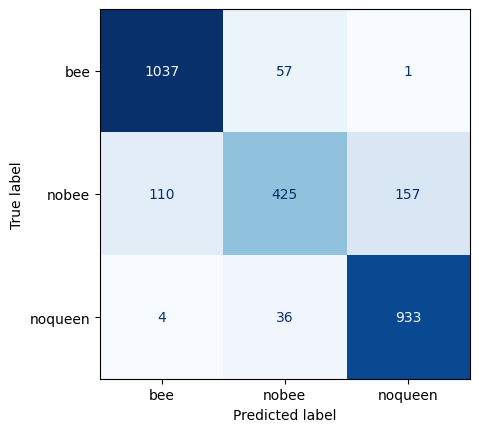

KNN (STFTs features) - Accuracy: 86.78%
Saved: confusion_matrices\KNN_STFTs_features.png


0.8677536231884058

In [142]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(stfts_train_features, stfts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_stfts_knn = knn_classifier.predict(stfts_test_features)
report_confusion(stfts_test_labels, test_accuracy_stfts_knn, "KNN (STFTs features)")

Training time: 0.02 seconds


<Figure size 500x400 with 0 Axes>

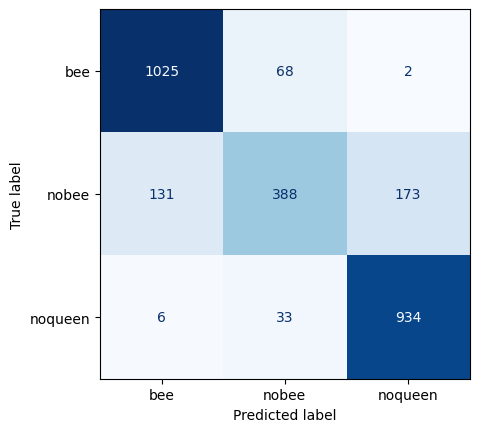

KNN (STFTs features scaled) - Accuracy: 85.04%
Saved: confusion_matrices\KNN_STFTs_features_scaled.png


0.8503623188405797

In [143]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(stfts_train_features_scaled, stfts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_stfts_knn = knn_classifier.predict(stfts_test_features_scaled)
report_confusion(stfts_test_labels, test_accuracy_stfts_knn, "KNN (STFTs features scaled)")

Training time: 81.39 seconds


<Figure size 500x400 with 0 Axes>

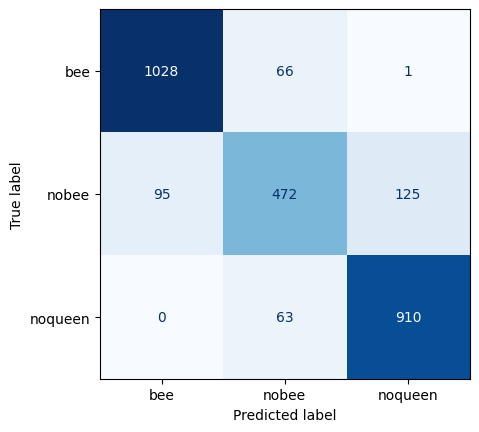

SVM RBF (STFTs features) - Accuracy: 87.32%
Saved: confusion_matrices\SVM_RBF_STFTs_features.png


0.8731884057971014

In [144]:
start_time = time.time()

svm_rbf_classifier = SVC(C=80, kernel='rbf', degree=3, gamma=0.08, coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

svm_rbf_classifier.fit(stfts_train_features, stfts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_svm_rbf = svm_rbf_classifier.predict(stfts_test_features)
report_confusion(stfts_test_labels, test_predictions_svm_rbf, "SVM RBF (STFTs features)")

Training time: 41.80 seconds


<Figure size 500x400 with 0 Axes>

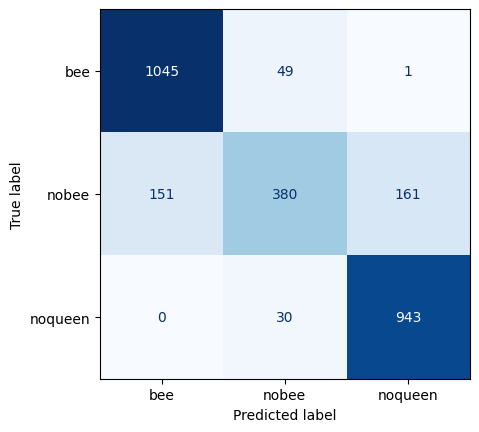

Random Forest (STFTs features) - Accuracy: 85.80%
Saved: confusion_matrices\Random_Forest_STFTs_features.png


0.8579710144927536

In [145]:
start_time = time.time()

rf_classifier = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                       min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                       max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                       n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                       ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier.fit(stfts_train_features, stfts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_stfts_rf = rf_classifier.predict(stfts_test_features)
report_confusion(stfts_test_labels, test_accuracy_stfts_rf, "Random Forest (STFTs features)")

Training time: 453.85 seconds


<Figure size 500x400 with 0 Axes>

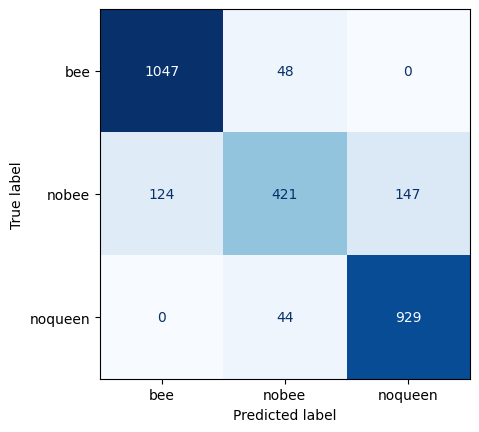

Extra Trees (STFTs features) - Accuracy: 86.85%
Saved: confusion_matrices\Extra_Trees_STFTs_features.png


0.8684782608695653

In [146]:
start_time = time.time()

et_classifier = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

et_classifier.fit(stfts_train_features, stfts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_et = et_classifier.predict(stfts_test_features)
report_confusion(stfts_test_labels, test_predictions_et, "Extra Trees (STFTs features)")

# FFTs + STFTs

In [147]:
# Kiểm tra và đảm bảo số lượng mẫu khớp nhau
print(f"FFTs train features shape: {train_features_fft.shape}")
print(f"STFTs train features shape: {stfts_train_features.shape}")
print(f"FFTs test features shape: {test_features_fft.shape}")
print(f"STFTs test features shape: {stfts_test_features.shape}")

# Kiểm tra labels có khớp không
if np.array_equal(train_labels_fft, stfts_train_labels) and np.array_equal(test_labels_fft, stfts_test_labels):
    print("✓ Labels are consistent between FFTs and STFTs")
    combined_train_labels = train_labels_fft
    combined_test_labels = test_labels_fft
else:
    print("⚠ Warning: Labels are not consistent, using FFTs labels")
    combined_train_labels = train_labels_fft
    combined_test_labels = test_labels_fft

# Concat FFTs và STFTs features
combined_train_features_ffts_stfts = np.hstack((train_features_fft, stfts_train_features))
combined_test_features_ffts_stfts = np.hstack((test_features_fft, stfts_test_features))

print(f"\nCombined FFTs+STFTs train features shape: {combined_train_features_ffts_stfts.shape}")
print(f"Combined FFTs+STFTs test features shape: {combined_test_features_ffts_stfts.shape}")

# Chuẩn hóa dữ liệu
scaler_combined = StandardScaler()
combined_train_features_scaled = scaler_combined.fit_transform(combined_train_features_ffts_stfts)
combined_test_features_scaled = scaler_combined.transform(combined_test_features_ffts_stfts)

print("Feature combination completed!")


FFTs train features shape: (11032, 257)
STFTs train features shape: (11032, 2049)
FFTs test features shape: (2760, 257)
STFTs test features shape: (2760, 2049)
✓ Labels are consistent between FFTs and STFTs

Combined FFTs+STFTs train features shape: (11032, 2306)
Combined FFTs+STFTs test features shape: (2760, 2306)
Feature combination completed!


FFTs + STFTs - KNN


Training time: 0.03 seconds


<Figure size 500x400 with 0 Axes>

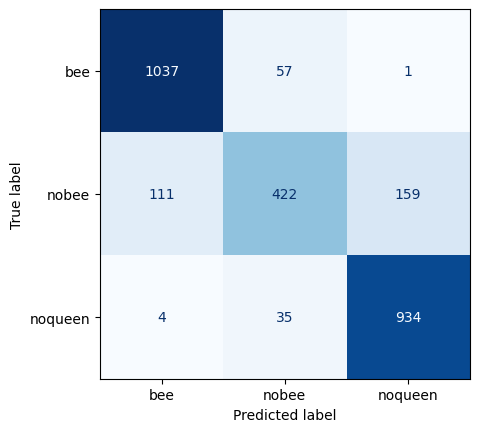

KNN (FFTs+STFTs features) - Accuracy: 86.70%
Saved: confusion_matrices\KNN_FFTsSTFTs_features.png


0.8670289855072464

In [148]:
start_time = time.time()

knn_classifier_combined = KNeighborsClassifier(n_neighbors=5)
knn_classifier_combined.fit(combined_train_features_ffts_stfts, combined_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_combined_knn = knn_classifier_combined.predict(combined_test_features_ffts_stfts)
report_confusion(combined_test_labels, test_pred_combined_knn, "KNN (FFTs+STFTs features)")

Training time: 0.03 seconds


<Figure size 500x400 with 0 Axes>

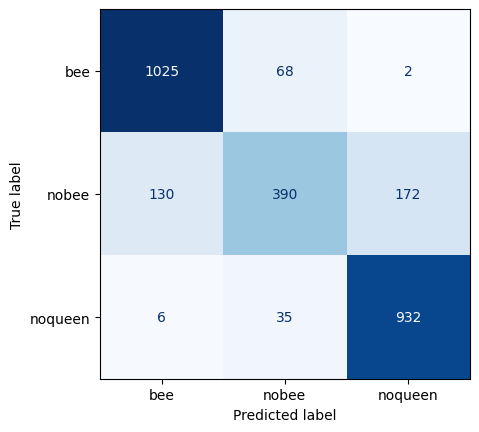

KNN (FFTs+STFTs features scaled) - Accuracy: 85.04%
Saved: confusion_matrices\KNN_FFTsSTFTs_features_scaled.png


0.8503623188405797

In [149]:
start_time = time.time()

knn_classifier_combined_scaled = KNeighborsClassifier(n_neighbors=5)
knn_classifier_combined_scaled.fit(combined_train_features_scaled, combined_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_combined_knn_scaled = knn_classifier_combined_scaled.predict(combined_test_features_scaled)
report_confusion(combined_test_labels, test_pred_combined_knn_scaled, "KNN (FFTs+STFTs features scaled)")

FFTs + STFTs - SVM


Training time: 122.58 seconds


<Figure size 500x400 with 0 Axes>

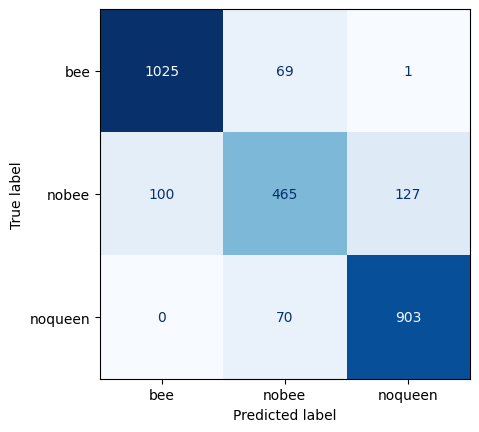

SVM RBF (FFTs+STFTs features) - Accuracy: 86.70%
Saved: confusion_matrices\SVM_RBF_FFTsSTFTs_features.png


0.8670289855072464

In [150]:
start_time = time.time()

svm_rbf_classifier_combined = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                                   probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                                   max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

svm_rbf_classifier_combined.fit(combined_train_features_ffts_stfts, combined_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_svm_combined = svm_rbf_classifier_combined.predict(combined_test_features_ffts_stfts)
report_confusion(combined_test_labels, test_predictions_svm_combined, "SVM RBF (FFTs+STFTs features)")

Training time: 166.93 seconds


<Figure size 500x400 with 0 Axes>

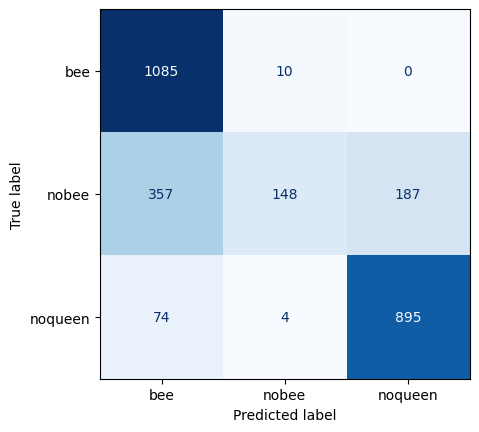

SVM RBF (FFTs+STFTs features scaled) - Accuracy: 77.10%
Saved: confusion_matrices\SVM_RBF_FFTsSTFTs_features_scaled.png


0.7710144927536232

In [151]:
start_time = time.time()

svm_rbf_classifier_combined_scaled = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

svm_rbf_classifier_combined_scaled.fit(combined_train_features_scaled, combined_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_svm_combined_scaled = svm_rbf_classifier_combined_scaled.predict(combined_test_features_scaled)
report_confusion(combined_test_labels, test_predictions_svm_combined_scaled, "SVM RBF (FFTs+STFTs features scaled)")

FFTs + STFTs - RF


Training time: 49.73 seconds


<Figure size 500x400 with 0 Axes>

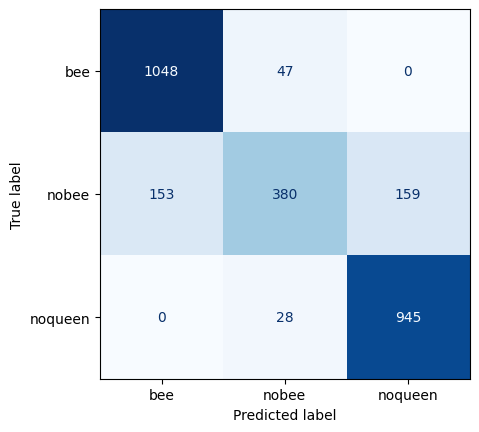

Random Forest (FFTs+STFTs features) - Accuracy: 85.98%
Saved: confusion_matrices\Random_Forest_FFTsSTFTs_features.png


0.8597826086956522

In [152]:
start_time = time.time()

rf_classifier_combined = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                                min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                                max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                                n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                                ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier_combined.fit(combined_train_features_ffts_stfts, combined_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_combined_rf = rf_classifier_combined.predict(combined_test_features_ffts_stfts)
report_confusion(combined_test_labels, test_pred_combined_rf, "Random Forest (FFTs+STFTs features)")

Training time: 616.17 seconds


<Figure size 500x400 with 0 Axes>

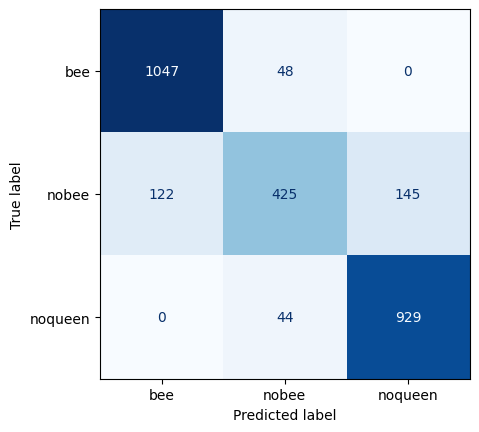

Extra Trees (FFTs+STFTs features) - Accuracy: 86.99%
Saved: confusion_matrices\Extra_Trees_FFTsSTFTs_features.png


0.869927536231884

In [153]:
start_time = time.time()

et_classifier_combined = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                              min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                              bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                              class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

et_classifier_combined.fit(combined_train_features_ffts_stfts, combined_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_et_combined = et_classifier_combined.predict(combined_test_features_ffts_stfts)
report_confusion(combined_test_labels, test_predictions_et_combined, "Extra Trees (FFTs+STFTs features)")

# CQT

In [154]:
def compute_cqt_features(signal_in, sample_rate, hop_length=512, fmin=None, 
                         n_bins=84, bins_per_octave=12, apply_log=True):
    """
    Tính đặc trưng CQT của tín hiệu:
      - Sử dụng librosa.cqt để tính ma trận CQT, lấy giá trị magnitude.
      - (Tùy chọn) Áp dụng log scaling để giảm phạm vi giá trị.
      - Trung bình theo trục thời gian (axis=1) để thu được vector đặc trưng có kích thước (n_bins,).
      
    Nếu fmin không được chỉ định, librosa sẽ tự động sử dụng fmin mặc định.
    """
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate, hop_length=hop_length,
                                    fmin=fmin, n_bins=n_bins, bins_per_octave=bins_per_octave))
    if apply_log:
        cqt_matrix = np.log(cqt_matrix + 1e-8)
    # Trung bình theo trục thời gian (tính trung bình các cột)
    features = np.mean(cqt_matrix, axis=1)
    return features


In [155]:
def load_cqt_features_from_directory(directory, sample_rate=22050, hop_length=512, 
                                     fmin=None, n_bins=84, bins_per_octave=12, output_dir=None, dataset_type='train'):
    # Kiểm tra nếu file đã tồn tại, thì load lại
    features_file = os.path.join(output_dir, f'cqt_features_{dataset_type}.pkl')
    labels_file = os.path.join(output_dir, f'cqt_labels_{dataset_type}.pkl')
    
    if os.path.exists(features_file) and os.path.exists(labels_file):
        print(f"Loading {dataset_type} data from .pkl files...")
        features = joblib.load(features_file)
        labels = joblib.load(labels_file)
    else:
        print(f"Extracting {dataset_type} data...")
        start_time = time.time()
        labels = []
        features = []
        
        for label in ['bee', 'nobee', 'noqueen']:
            path = os.path.join(directory, label)
            for file in os.listdir(path):
                file_path = os.path.join(path, file)
                signal, sr = librosa.load(file_path, sr=sample_rate)
                
                # Compute CQT features
                cqt_feature = compute_cqt_features(signal, sr, hop_length=hop_length, 
                                                   fmin=fmin, n_bins=n_bins, bins_per_octave=bins_per_octave, 
                                                   apply_log=True)
                
                features.append(cqt_feature)
                labels.append(label)

        features = np.array(features)
        labels = np.array(labels)
        
        # Lưu dữ liệu vào file .pkl nếu chưa tồn tại
        if output_dir:
            joblib.dump(features, features_file)
            joblib.dump(labels, labels_file)
        
        end_time = time.time()
        print(f"CQT extraction time: {end_time - start_time:.2f} seconds")
    
    return features, labels

train_features_cqt, train_labels_cqt = load_cqt_features_from_directory(train_path, sample_rate=22050,
                                                                        hop_length=512, fmin=None, n_bins=84, bins_per_octave=12, 
                                                                        output_dir=output_dir, dataset_type='train')
val_features_cqt, val_labels_cqt = load_cqt_features_from_directory(val_path, sample_rate=22050,
                                                                    hop_length=512, fmin=None, n_bins=84, bins_per_octave=12, 
                                                                    output_dir=output_dir, dataset_type='val')
test_features_cqt, test_labels_cqt = load_cqt_features_from_directory(test_path, sample_rate=22050,
                                                                      hop_length=512, fmin=None, n_bins=84, bins_per_octave=12, 
                                                                      output_dir=output_dir, dataset_type='test')

train_features_cqt = np.vstack((train_features_cqt, val_features_cqt))
train_labels_cqt = np.hstack((train_labels_cqt, val_labels_cqt))

Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...


In [156]:
train_features_cqt.shape[1]

84

In [157]:
scaler_cqt = StandardScaler()
train_features_cqt_scaled = scaler_cqt.fit_transform(train_features_cqt)
test_features_cqt_scaled  = scaler_cqt.transform(test_features_cqt)

CQT - KNN

Training time: 0.00 seconds


<Figure size 500x400 with 0 Axes>

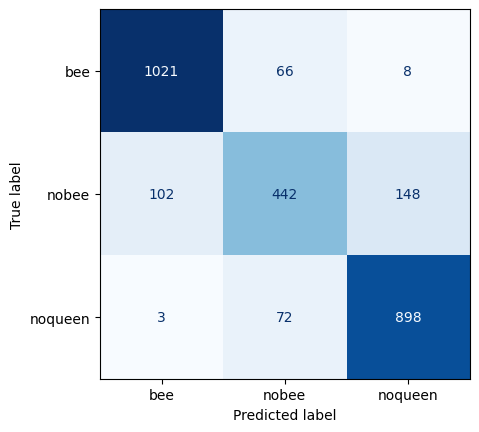

KNN (CQT features) - Accuracy: 85.54%
Saved: confusion_matrices\KNN_CQT_features.png


0.8554347826086957

In [158]:
start_time = time.time()

knn_classifier_cqt = KNeighborsClassifier(n_neighbors=1, weights='uniform', algorithm='auto', leaf_size=30, p=2, 
                                      metric='minkowski', metric_params=None, n_jobs=None)

knn_classifier_cqt.fit(train_features_cqt_scaled, train_labels_cqt)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_cqt_knn = knn_classifier_cqt.predict(test_features_cqt_scaled)

report_confusion(test_labels_cqt, test_pred_cqt_knn, "KNN (CQT features)")

CQT - SVM

Training time: 2.13 seconds


<Figure size 500x400 with 0 Axes>

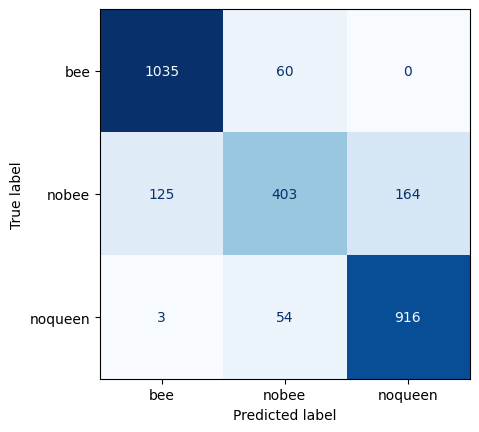

SVM RBF (CQT features) - Accuracy: 85.29%
Saved: confusion_matrices\SVM_RBF_CQT_features.png


0.8528985507246377

In [159]:
start_time = time.time()

svm_classifier_cqt = SVC(C=100, kernel='rbf', gamma='auto', random_state=42)
svm_classifier_cqt.fit(train_features_cqt, train_labels_cqt)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_cqt_svm = svm_classifier_cqt.predict(test_features_cqt)

report_confusion(test_labels_cqt, test_pred_cqt_svm, "SVM RBF (CQT features)")

Training time: 2.00 seconds


<Figure size 500x400 with 0 Axes>

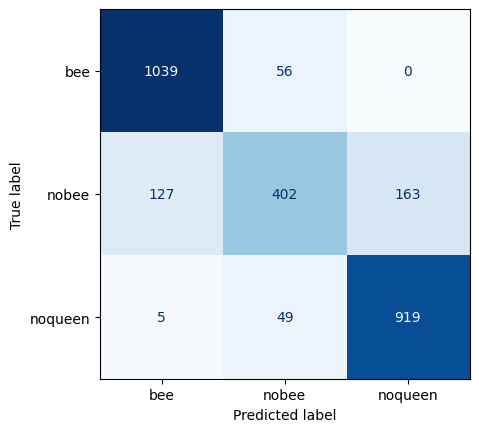

SVM RBF (CQT features scaled) - Accuracy: 85.51%
Saved: confusion_matrices\SVM_RBF_CQT_features_scaled.png


0.855072463768116

In [160]:
start_time = time.time()

svm_classifier_cqt = SVC(C=100, kernel='rbf', gamma='auto', random_state=42)
svm_classifier_cqt.fit(train_features_cqt_scaled, train_labels_cqt)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_cqt_svm = svm_classifier_cqt.predict(test_features_cqt_scaled)

report_confusion(test_labels_cqt, test_pred_cqt_svm, "SVM RBF (CQT features scaled)")

CQT - LR

Training time: 0.48 seconds


<Figure size 500x400 with 0 Axes>

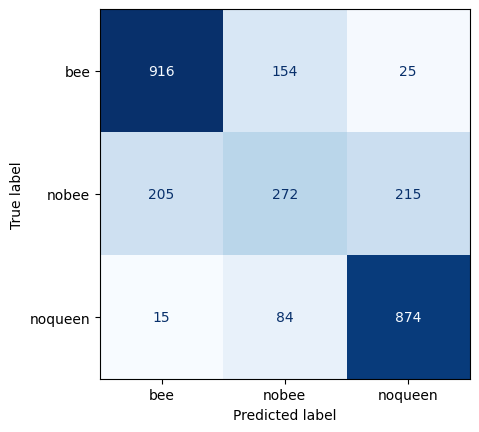

Logistic Regression (CQT features) - Accuracy: 74.71%
Saved: confusion_matrices\Logistic_Regression_CQT_features.png


0.7471014492753624

In [161]:
start_time = time.time()

lr_classifier_cqt =LogisticRegression(penalty='l2', dual=False, tol=0.0001, C=1.0, 
                                      fit_intercept=True, intercept_scaling=1, 
                                      class_weight=None, random_state=None, solver='lbfgs', 
                                      max_iter=500, multi_class='deprecated', verbose=0, 
                                      warm_start=False, n_jobs=None, l1_ratio=None)

lr_classifier_cqt.fit(train_features_cqt_scaled, train_labels_cqt)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_cqt_lr = lr_classifier_cqt.predict(test_features_cqt_scaled)

report_confusion(test_labels_cqt, test_pred_cqt_lr, "Logistic Regression (CQT features)")

CQT - RF

Training time: 13.78 seconds


<Figure size 500x400 with 0 Axes>

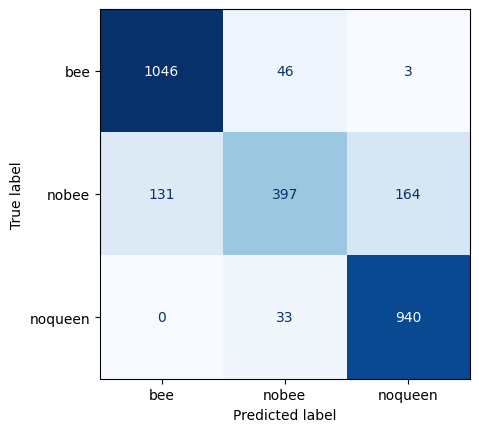

Random Forest (CQT features) - Accuracy: 86.34%
Saved: confusion_matrices\Random_Forest_CQT_features.png


0.8634057971014493

In [162]:
start_time = time.time()

rf_classifier_cqt = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, 
                                       min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, 
                                       max_features='sqrt', max_leaf_nodes=None, min_impurity_decrease=0.0, 
                                       bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, 
                                       warm_start=False, class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier_cqt.fit(train_features_cqt, train_labels_cqt)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_cqt_rf = rf_classifier_cqt.predict(test_features_cqt)

report_confusion(test_labels_cqt, test_pred_cqt_rf, "Random Forest (CQT features)")

CQT - ET

Training time: 15.05 seconds


<Figure size 500x400 with 0 Axes>

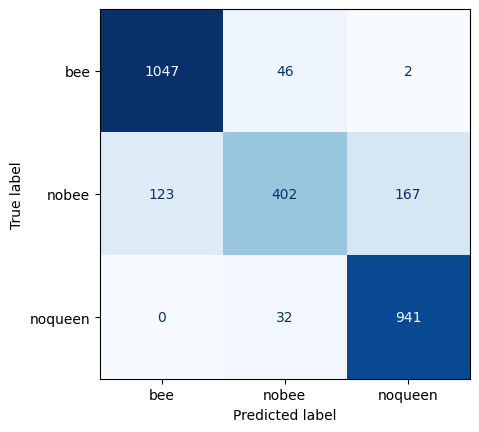

Extra Trees (CQT features) - Accuracy: 86.59%
Saved: confusion_matrices\Extra_Trees_CQT_features.png


0.8659420289855072

In [163]:
start_time = time.time()

et_classifier_cqt = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

et_classifier_cqt.fit(train_features_cqt_scaled, train_labels_cqt)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_cqt_et = et_classifier_cqt.predict(test_features_cqt_scaled)

report_confusion(test_labels_cqt, test_pred_cqt_et, "Extra Trees (CQT features)")

# FFTs + CQT

In [164]:
def pre_emphasis(signal_in, pre_emph=0.97):
    """
    Áp dụng pre-emphasis để nhấn mạnh các tần số cao.
    
    Args:
        signal_in: Tín hiệu đầu vào
        pre_emph: Hệ số pre-emphasis, mặc định là 0.97
        
    Returns:
        Tín hiệu sau khi áp dụng pre-emphasis
    """
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing(signal_in, sample_rate, frame_size=0.025, hop_length=256, overlap=0.6):
    """
    Chia tín hiệu thành các frame với kích thước và bước nhảy xác định.
    
    Args:
        signal_in: Tín hiệu đầu vào
        sample_rate: Tần số lấy mẫu
        frame_size: Kích thước frame (giây hoặc số mẫu nếu frame_size > 1)
        hop_length: Bước nhảy (giây hoặc số mẫu nếu hop_length > 1)
                    Nếu None, sẽ được tính dựa trên overlap
        overlap: Tỷ lệ chồng lấp giữa các frame, mặc định là 0.6 (60%)
                Chỉ được sử dụng khi hop_length là None
        
    Returns:
        Mảng 2D chứa các frame
    """
    # Xác định kích thước frame trong số mẫu
    if frame_size <= 1:  # Nếu frame_size <= 1, xem như đơn vị là giây
        frame_length = int(round(frame_size * sample_rate))
    else:  # Ngược lại, xem như đơn vị là số mẫu
        frame_length = int(frame_size)
    
    # Xác định hop_length (bước nhảy) trong số mẫu
    if hop_length is None:
        # Tính hop_length từ overlap
        frame_step = int(frame_length * (1 - overlap))
    elif hop_length <= 1:  # Nếu hop_length <= 1, xem như đơn vị là giây
        frame_step = int(round(hop_length * sample_rate))
    else:  # Ngược lại, xem như đơn vị là số mẫu
        frame_step = int(hop_length)
    
    # Đảm bảo hop_length không quá nhỏ
    frame_step = max(1, frame_step)
    
    signal_length = len(signal_in)
    
    # Tính số frame cần thiết
    num_frames = int(np.ceil((signal_length - frame_length) / frame_step)) + 1
    
    # Đệm tín hiệu để đảm bảo có đủ mẫu cho tất cả các frame
    pad_signal_length = (num_frames - 1) * frame_step + frame_length
    pad_zeros = np.zeros(pad_signal_length - signal_length)
    padded_signal = np.concatenate([signal_in, pad_zeros])
    
    # Tạo indices cho từng frame
    indices = np.tile(np.arange(0, frame_length), (num_frames, 1)) + \
              np.tile(np.arange(0, num_frames * frame_step, frame_step), (frame_length, 1)).T
    
    # Đảm bảo indices không vượt quá độ dài tín hiệu
    indices = np.minimum(indices, len(padded_signal) - 1)
    
    # Trích xuất các frame từ tín hiệu
    frames = padded_signal[indices.astype(np.int32, copy=False)]
    
    return frames

def windowing(frames, window_type='bartlett'):
    """
    Áp dụng cửa sổ cho mỗi frame.
    
    Args:
        frames: Mảng 2D chứa các frame
        window_type: Loại cửa sổ ('hamming', 'hanning', 'blackman', 'bartlett')
        
    Returns:
        Các frame sau khi áp dụng cửa sổ
    """
    frame_length = frames.shape[1]
    
    if window_type == 'hamming':
        window = np.hamming(frame_length)
    elif window_type == 'hanning':
        window = np.hanning(frame_length)
    elif window_type == 'blackman':
        window = np.blackman(frame_length)
    elif window_type == 'bartlett':
        window = np.bartlett(frame_length)
    else:
        window = np.hamming(frame_length)  # Mặc định là hamming
        
    return frames * window

def fft_frames(frames, NFFT=512):
    """
    Tính FFT cho mỗi frame và lấy giá trị magnitude.
    
    Args:
        frames: Mảng 2D chứa các frame
        NFFT: Kích thước FFT (số điểm FFT)
        
    Returns:
        Magnitude của FFT
    """
    return np.absolute(np.fft.rfft(frames, NFFT))

def compute_fft_features(signal_in, sample_rate, frame_size=0.025, hop_length=256, 
                         overlap=0.6, NFFT=512, apply_log=True, window_type='bartlett',
                         normalize=False):
    """
    Tính toán đặc trưng FFT cho tín hiệu âm thanh:
      - Pre-emphasis, Framing, Windowing.
      - Tính FFT cho từng frame và lấy giá trị magnitude.
      - Trung bình các frame để có vector đặc trưng ổn định.
      
    Args:
        signal_in: Tín hiệu đầu vào
        sample_rate: Tần số lấy mẫu
        frame_size: Kích thước frame (giây hoặc số mẫu nếu > 1)
        hop_length: Bước nhảy (giây hoặc số mẫu nếu > 1). Nếu None, sẽ sử dụng overlap
        overlap: Tỷ lệ chồng lấp giữa các frame (0-1)
        NFFT: Số điểm FFT
        apply_log: Áp dụng logarit cho đặc trưng
        window_type: Loại cửa sổ ('hamming', 'hanning', 'blackman', 'bartlett')
        normalize: Chuẩn hóa đặc trưng
        
    Returns:
        Vector đặc trưng có kích thước (NFFT//2+1,)
    """
    # Áp dụng pre-emphasis
    emphasized_signal = pre_emphasis(signal_in)
    
    # Chia tín hiệu thành các frame
    frames = framing(emphasized_signal, sample_rate, frame_size, hop_length, overlap)
    
    # Áp dụng cửa sổ
    windowed_frames = windowing(frames, window_type)
    
    # Tính FFT
    mag_frames = fft_frames(windowed_frames, NFFT)
    
    # Trung bình theo các frame
    fft_feature = np.mean(mag_frames, axis=0)
    
    # Áp dụng logarithm (nếu cần)
    if apply_log:
        fft_feature = np.log(fft_feature + 1e-8)  # Thêm epsilon để tránh log(0)
    
    # Chuẩn hóa (nếu cần)
    if normalize:
        fft_feature = (fft_feature - np.mean(fft_feature)) / (np.std(fft_feature) + 1e-8)
    
    return fft_feature

def compute_cqt_features(signal_in, sample_rate, hop_length=512, fmin=None, 
                         n_bins=84, bins_per_octave=12, apply_log=True, normalize=False):
    """
    Tính đặc trưng CQT của tín hiệu:
      - Sử dụng librosa.cqt để tính ma trận CQT, lấy giá trị magnitude.
      - (Tùy chọn) Áp dụng log scaling để giảm phạm vi giá trị.
      - Trung bình theo trục thời gian (axis=1) để thu được vector đặc trưng có kích thước (n_bins,).
      
    Args:
        signal_in: Tín hiệu đầu vào
        sample_rate: Tần số lấy mẫu
        hop_length: Bước nhảy giữa các cửa sổ phân tích liên tiếp
        fmin: Tần số thấp nhất (Hz). Nếu None, librosa sẽ sử dụng mặc định
        n_bins: Số lượng bin tần số
        bins_per_octave: Số lượng bin cho mỗi quãng 8
        apply_log: Áp dụng logarit cho đặc trưng
        normalize: Chuẩn hóa đặc trưng
        
    Returns:
        Vector đặc trưng CQT có kích thước (n_bins,)
    """
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate, hop_length=hop_length,
                                    fmin=fmin, n_bins=n_bins, bins_per_octave=bins_per_octave))
    
    # Trung bình theo trục thời gian (tính trung bình các cột)
    cqt_feature = np.mean(cqt_matrix, axis=1)
    
    # Áp dụng logarithm (nếu cần)
    if apply_log:
        cqt_feature = np.log(cqt_feature + 1e-8)  # Thêm epsilon để tránh log(0)
    
    # Chuẩn hóa (nếu cần)
    if normalize:
        cqt_feature = (cqt_feature - np.mean(cqt_feature)) / (np.std(cqt_feature) + 1e-8)
    
    return cqt_feature

def compute_features(signal_in, sample_rate, frame_size=0.025, hop_length=512, 
                     overlap=0.6, NFFT=512, window_type='bartlett', normalize=False,
                     fmin=None, n_bins=84, bins_per_octave=12, apply_log=True):
    """
    Tính toán và kết hợp đặc trưng FFT và CQT cho tín hiệu âm thanh.
    
    Args:
        signal_in: Tín hiệu đầu vào
        sample_rate: Tần số lấy mẫu
        frame_size: Kích thước frame cho FFT (giây hoặc số mẫu nếu > 1)
        hop_length: Bước nhảy (giây hoặc số mẫu nếu > 1)
        overlap: Tỷ lệ chồng lấp giữa các frame (0-1) cho FFT
        NFFT: Số điểm FFT
        window_type: Loại cửa sổ ('hamming', 'hanning', 'blackman', 'bartlett')
        normalize: Chuẩn hóa đặc trưng
        fmin: Tần số thấp nhất (Hz) cho CQT
        n_bins: Số lượng bin tần số cho CQT
        bins_per_octave: Số lượng bin cho mỗi quãng 8 cho CQT
        apply_log: Áp dụng logarit cho đặc trưng
        
    Returns:
        Vector đặc trưng kết hợp FFT và CQT
    """
    # Tính đặc trưng FFT
    fft_feature = compute_fft_features(
        signal_in, sample_rate, frame_size=frame_size, hop_length=hop_length, 
        overlap=overlap, NFFT=NFFT, window_type=window_type,
        apply_log=apply_log, normalize=normalize
    )
    
    # Tính đặc trưng CQT
    cqt_feature = compute_cqt_features(
        signal_in, sample_rate, hop_length=hop_length, fmin=fmin,
        n_bins=n_bins, bins_per_octave=bins_per_octave,
        apply_log=apply_log, normalize=normalize
    )
    
    # Kết hợp hai đặc trưng
    combined_feature = np.concatenate((fft_feature, cqt_feature))
    
    return combined_feature

def load_features_from_directory(directory, sample_rate=22050, NFFT=512, 
                                 frame_size=0.025, hop_length=512, overlap=0.6,
                                 window_type='bartlett', output_dir=None, 
                                 dataset_type='train', normalize=False,
                                 fmin=None, n_bins=84, bins_per_octave=12):
    """
    Duyệt qua các file âm thanh trong thư mục và tính đặc trưng kết hợp FFT và CQT cho mỗi file.
    
    Args:
        directory: Thư mục chứa dữ liệu âm thanh
        sample_rate: Tần số lấy mẫu
        NFFT: Số điểm FFT
        frame_size: Kích thước frame (giây hoặc số mẫu nếu > 1)
        hop_length: Bước nhảy (giây hoặc số mẫu nếu > 1)
        overlap: Tỷ lệ chồng lấp giữa các frame (0-1)
        window_type: Loại cửa sổ ('hamming', 'hanning', 'blackman', 'bartlett')
        output_dir: Thư mục đầu ra để lưu đặc trưng
        dataset_type: Loại tập dữ liệu ('train', 'test', 'val')
        normalize: Chuẩn hóa đặc trưng
        fmin: Tần số thấp nhất (Hz) cho CQT
        n_bins: Số lượng bin tần số cho CQT
        bins_per_octave: Số lượng bin cho mỗi quãng 8 cho CQT
        
    Returns:
        features: Mảng đặc trưng kết hợp
        labels: Nhãn tương ứng
    """
    # Kiểm tra nếu file đã tồn tại, thì load lại
    hop_str = f"{hop_length}" if hop_length else f"overlap{overlap}"
    features_file = os.path.join(output_dir, f'combined_features_{dataset_type}_nfft{NFFT}_hop{hop_str}_bins{n_bins}.pkl')
    labels_file = os.path.join(output_dir, f'combined_labels_{dataset_type}_nfft{NFFT}_hop{hop_str}_bins{n_bins}.pkl')
    
    if os.path.exists(features_file) and os.path.exists(labels_file):
        print(f"Loading {dataset_type} data from .pkl files...")
        features = joblib.load(features_file)
        labels = joblib.load(labels_file)
    else:
        print(f"Extracting {dataset_type} data...")
        start_time = time.time()
        labels = []
        features = []
        
        for label in ['bee', 'nobee', 'noqueen']:
            path = os.path.join(directory, label)
            if not os.path.exists(path):
                print(f"Warning: Path {path} does not exist. Skipping.")
                continue
                
            for file in os.listdir(path):
                if not file.endswith(('.wav', '.mp3', '.flac', '.ogg')):
                    continue
                    
                file_path = os.path.join(path, file)
                try:
                    signal, sr = librosa.load(file_path, sr=sample_rate)
                    
                    # Tính toán đặc trưng kết hợp FFT và CQT
                    combined_feature = compute_features(
                        signal, sr, frame_size=frame_size, hop_length=hop_length, 
                        overlap=overlap, NFFT=NFFT, window_type=window_type,
                        normalize=normalize, fmin=fmin, n_bins=n_bins, 
                        bins_per_octave=bins_per_octave
                    )
                    
                    features.append(combined_feature)
                    labels.append(label)
                except Exception as e:
                    print(f"Error processing file {file_path}: {str(e)}")
        
        features = np.array(features)
        labels = np.array(labels)
        
        # Lưu dữ liệu vào file .pkl nếu chưa tồn tại
        if output_dir:
            os.makedirs(output_dir, exist_ok=True)
            joblib.dump(features, features_file)
            joblib.dump(labels, labels_file)
        
        end_time = time.time()
        print(f"Feature extraction time: {end_time - start_time:.2f} seconds")
        print(f"Features shape: {features.shape}, Labels shape: {labels.shape}")
    
    return features, labels

# Trích xuất đặc trưng kết hợp cho tập dữ liệu
train_features, train_labels = load_features_from_directory(
    train_path, sample_rate=22050, NFFT=2048, 
    hop_length=512, fmin=None, n_bins=96, bins_per_octave=12,
    output_dir=output_dir, dataset_type='train'
)

val_features, val_labels = load_features_from_directory(
    val_path, sample_rate=22050, NFFT=2048, 
    hop_length=512, fmin=None, n_bins=96, bins_per_octave=12,
    output_dir=output_dir, dataset_type='val'
)

test_features, test_labels = load_features_from_directory(
    test_path, sample_rate=22050, NFFT=2048, 
    hop_length=512, fmin=None, n_bins=96, bins_per_octave=12,
    output_dir=output_dir, dataset_type='test'
)

train_features = np.vstack((train_features, val_features))
train_labels = np.hstack((train_labels, val_labels))

Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...


In [165]:
def separate_fft_cqt_features(combined_features, nfft=2048, n_bins=96):
    """
    Tách đặc trưng kết hợp thành đặc trưng FFT và CQT riêng biệt.
    
    Args:
        combined_features: Mảng đặc trưng kết hợp FFT và CQT
        nfft: Số điểm FFT đã sử dụng khi tạo đặc trưng
        n_bins: Số lượng bin CQT đã sử dụng khi tạo đặc trưng
        
    Returns:
        fft_features: Mảng đặc trưng FFT
        cqt_features: Mảng đặc trưng CQT
    """
    fft_length = nfft // 2 + 1
    
    # Kiểm tra shape của mảng đầu vào
    if combined_features.ndim == 1:
        # Nếu là vector đơn, tách trực tiếp
        fft_features = combined_features[:fft_length]
        cqt_features = combined_features[fft_length:]
    else:
        # Nếu là batch, tách từng mẫu
        fft_features = combined_features[:, :fft_length]
        cqt_features = combined_features[:, fft_length:]
    
    return fft_features, cqt_features

# Ví dụ cách sử dụng:
train_fft, train_cqt = separate_fft_cqt_features(train_features, nfft=2048, n_bins=96)
test_fft, test_cqt = separate_fft_cqt_features(test_features, nfft=2048, n_bins=96)

# In kích thước để kiểm tra
print(f"Train combined features shape: {train_features.shape}")
print(f"Train FFT features shape: {train_fft.shape}")
print(f"Train CQT features shape: {train_cqt.shape}")

print(f"Test combined features shape: {test_features.shape}")
print(f"Test FFT features shape: {test_fft.shape}")
print(f"Test CQT features shape: {test_cqt.shape}")

Train combined features shape: (11032, 1121)
Train FFT features shape: (11032, 1025)
Train CQT features shape: (11032, 96)
Test combined features shape: (2760, 1121)
Test FFT features shape: (2760, 1025)
Test CQT features shape: (2760, 96)


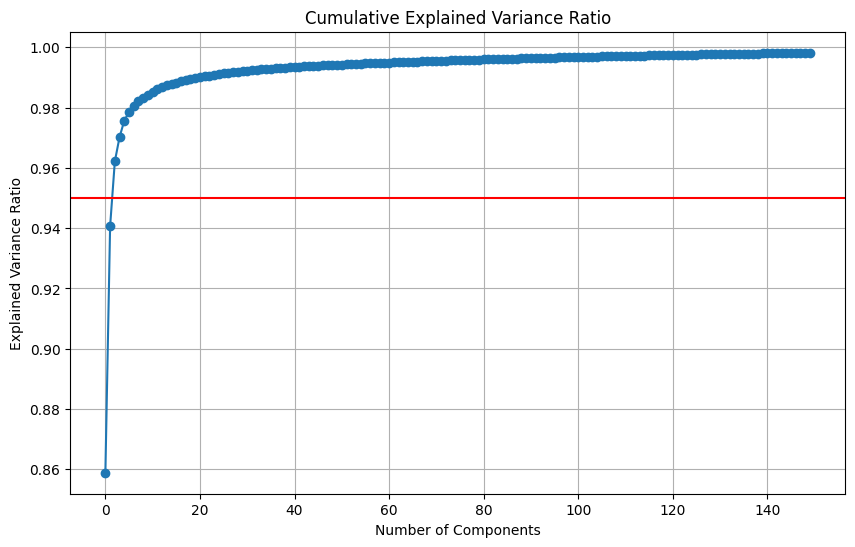

Number of components needed to explain 95% variance: 3
Top 5 principal components explain: 0.9757 of variance
Original FFT features shape: (11032, 1025)
PCA FFT features shape: (11032, 150)
Combined features shape: (11032, 246)
Test combined features shape: (2760, 246)


In [166]:
def apply_pca_to_fft(fft_features, test_features=None, n_components=100, plot=True):
    """
    Áp dụng PCA để giảm số chiều của đặc trưng FFT.
    
    Args:
        fft_features: Mảng đặc trưng FFT cho tập huấn luyện
        test_features: Mảng đặc trưng FFT cho tập kiểm tra (nếu có)
        n_components: Số lượng thành phần chính muốn giữ lại
        plot: Vẽ đồ thị tỷ lệ phương sai giải thích được
        
    Returns:
        fft_pca: Đặc trưng FFT sau khi áp dụng PCA cho tập huấn luyện
        test_pca: Đặc trưng FFT sau khi áp dụng PCA cho tập kiểm tra (nếu có)
        pca: Đối tượng PCA đã được huấn luyện
    """
    from sklearn.decomposition import PCA
    
    # Khởi tạo và huấn luyện PCA
    pca = PCA(n_components=n_components, random_state=53940)
    fft_pca = pca.fit_transform(fft_features)
    
    # Áp dụng cho tập kiểm tra (nếu có)
    test_pca = None
    if test_features is not None:
        test_pca = pca.transform(test_features)
    
    # Vẽ đồ thị tỷ lệ phương sai giải thích được
    if plot:
        explained_variance_ratio = pca.explained_variance_ratio_
        cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
        
        plt.figure(figsize=(10, 6))
        plt.plot(cumulative_variance_ratio, marker='o')
        plt.axhline(y=0.95, color='r', linestyle='-')
        plt.grid(True)
        plt.title('Cumulative Explained Variance Ratio')
        plt.xlabel('Number of Components')
        plt.ylabel('Explained Variance Ratio')
        plt.show()
        
        # Tìm số lượng thành phần cần thiết để giải thích 95% phương sai
        n_components_95 = np.where(cumulative_variance_ratio >= 0.95)[0][0] + 1
        print(f"Number of components needed to explain 95% variance: {n_components_95}")
        
        # Hiển thị top 5 thành phần chính quan trọng nhất
        print(f"Top 5 principal components explain: {np.sum(explained_variance_ratio[:5]):.4f} of variance")
    
    return fft_pca, test_pca, pca

# Áp dụng PCA cho FFT features
train_fft_pca, test_fft_pca, fft_pca = apply_pca_to_fft(
    train_fft, test_features=test_fft, n_components=150
)

print(f"Original FFT features shape: {train_fft.shape}")
print(f"PCA FFT features shape: {train_fft_pca.shape}")

train_features = np.hstack((train_fft_pca, train_cqt))
test_features = np.hstack((test_fft_pca, test_cqt))

print(f"Combined features shape: {train_features.shape}")
print(f"Test combined features shape: {test_features.shape}")

In [167]:
scaler_cqt = StandardScaler()
train_features_scaled = scaler_cqt.fit_transform(train_features)
test_features_scaled  = scaler_cqt.transform(test_features)

Training time: 0.01 seconds


<Figure size 500x400 with 0 Axes>

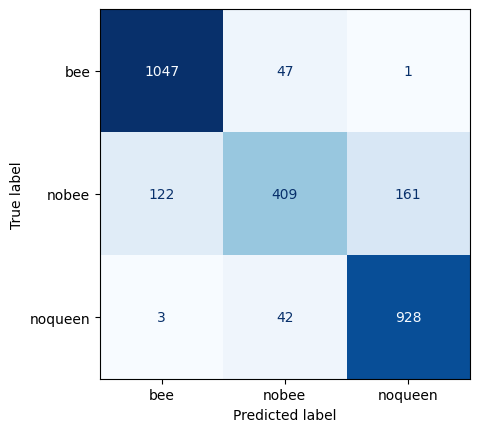

KNN (FFTs+CQT features) - Accuracy: 86.38%
Saved: confusion_matrices\KNN_FFTsCQT_features.png


0.863768115942029

In [168]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_knn = knn_classifier.predict(test_features)
report_confusion(test_labels, test_accuracy_knn, "KNN (FFTs+CQT features)")

Training time: 0.01 seconds


<Figure size 500x400 with 0 Axes>

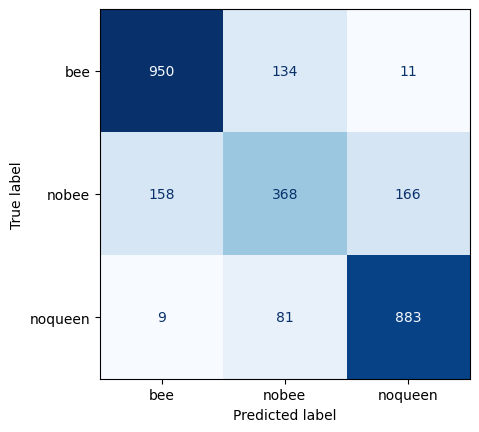

KNN (FFTs+CQT features scaled) - Accuracy: 79.75%
Saved: confusion_matrices\KNN_FFTsCQT_features_scaled.png


0.797463768115942

In [169]:
start_time = time.time()

knn_classifier_cqt = KNeighborsClassifier(n_neighbors=1, weights='uniform', algorithm='auto', leaf_size=30, p=2, 
                                      metric='minkowski', metric_params=None, n_jobs=None)

knn_classifier_cqt.fit(train_features_scaled, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_pred_cqt_knn = knn_classifier_cqt.predict(test_features_scaled)

report_confusion(test_labels, test_pred_cqt_knn, "KNN (FFTs+CQT features scaled)")

Training time: 3.77 seconds


<Figure size 500x400 with 0 Axes>

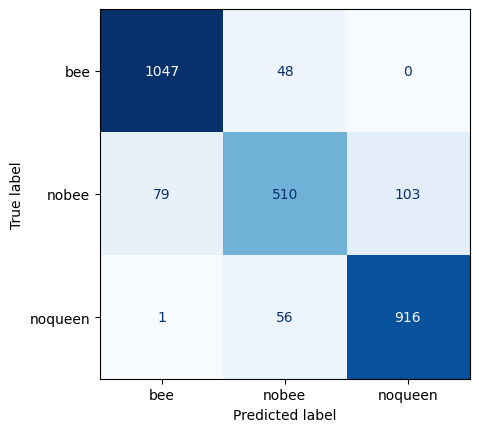

SVM RBF (FFTs+CQT features) - Accuracy: 89.60%
Saved: confusion_matrices\SVM_RBF_FFTsCQT_features.png


0.8960144927536232

In [170]:
start_time = time.time()

svm_rbf_classifier = SVC(C=71.19418600172986, kernel='rbf', degree=3, gamma=0.03752055855124281, 
                         coef0=0.0, shrinking=True, probability=False, tol=0.0005319450186421158, 
                         cache_size=500, class_weight=None, verbose=False, max_iter=-1, 
                         decision_function_shape='ovr', break_ties=False, random_state=42)


# Huấn luyện mô hình SVM trên dữ liệu kết hợp
svm_rbf_classifier.fit(train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(test_features)
report_confusion(test_labels, test_predictions_svm_rbf, "SVM RBF (FFTs+CQT features)")

Training time: 15.44 seconds


<Figure size 500x400 with 0 Axes>

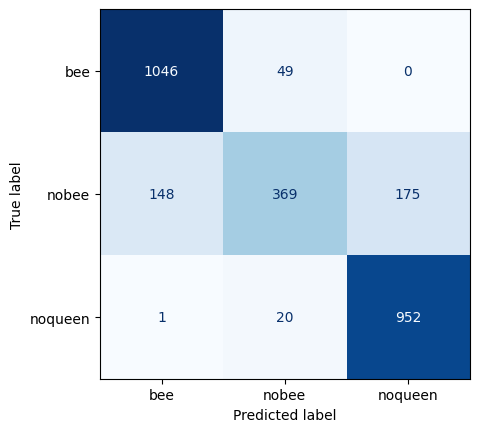

Random Forest (FFTs+CQT features) - Accuracy: 85.76%
Saved: confusion_matrices\Random_Forest_FFTsCQT_features.png


0.8576086956521739

In [171]:
start_time = time.time()

rf_classifier = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                       min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                       max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                       n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                       ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier.fit(train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_rf = rf_classifier.predict(test_features)
report_confusion(test_labels, test_accuracy_rf, "Random Forest (FFTs+CQT features)")

Training time: 45.06 seconds


<Figure size 500x400 with 0 Axes>

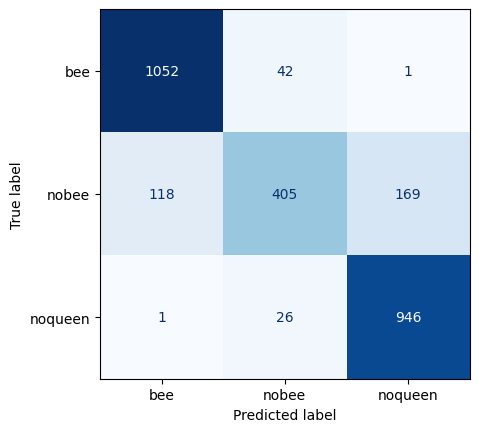

Extra Trees (FFTs+CQT features) - Accuracy: 87.07%
Saved: confusion_matrices\Extra_Trees_FFTsCQT_features.png


0.8706521739130435

In [172]:
start_time = time.time()

et_classifier = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

et_classifier.fit(train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_et = et_classifier.predict(test_features)
report_confusion(test_labels, test_predictions_et, "Extra Trees (FFTs+CQT features)")

# CQTs

In [173]:
import numpy as np
import librosa

def pre_emphasis(signal_in, pre_emph=0.97):
    """
    Áp dụng pre-emphasis để nhấn mạnh các tần số cao.
    """
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01):
    """
    Chia tín hiệu thành các frame có kích thước và bước nhảy xác định.
    """
    frame_length = int(round(frame_size * sample_rate))
    frame_step = int(round(frame_stride * sample_rate))
    signal_length = len(signal_in)
    
    num_frames = int(np.ceil(float(np.abs(signal_length - frame_length)) / frame_step)) + 1

    pad_signal_length = num_frames * frame_step + frame_length
    pad_signal = np.pad(signal_in, (0, pad_signal_length - signal_length), mode='constant')

    indices = np.arange(0, frame_length) + np.arange(0, num_frames * frame_step, frame_step)[:, None]
    frames = pad_signal[indices.astype(np.int32)]
    return frames

def windowing(frames):
    """
    Áp dụng cửa sổ Hamming cho mỗi frame.
    """
    frame_length = frames.shape[1]
    hamming = np.hamming(frame_length)
    return frames * hamming

def compute_cqts_features(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01, 
                          fmin=None, n_bins=84, bins_per_octave=12, apply_log=True):
    """
    Tính toán đặc trưng CQTs cho tín hiệu âm thanh:
      - Pre-emphasis trên toàn bộ tín hiệu
      - Framing và Windowing
      - Tính CQT cho toàn bộ tín hiệu (không tính theo từng frame vì CQT cần tín hiệu dài)
      - (Tùy chọn) Áp dụng log để giảm phạm vi giá trị.
    Trả về: vector đặc trưng có kích thước (n_bins,).
    """
    # Pre-emphasis trên toàn bộ tín hiệu
    emphasized_signal = pre_emphasis(signal_in)
    
    # Tính CQT cho toàn bộ tín hiệu đã pre-emphasize
    cqt_matrix = np.abs(librosa.cqt(emphasized_signal, sr=sample_rate, 
                                     fmin=fmin, n_bins=n_bins, 
                                     bins_per_octave=bins_per_octave,
                                     hop_length=512))
    
    # Trung bình theo thời gian để có vector đặc trưng
    cqts_feature = np.mean(cqt_matrix, axis=1)
    
    # Áp dụng log nếu cần, đảm bảo không có log(0)
    if apply_log:
        cqts_feature = np.log(np.maximum(cqts_feature, 1e-8))  # Thêm epsilon để tránh log(0)
    
    return cqts_feature

In [174]:
def load_cqts_features_from_directory(directory, sample_rate=22050, frame_size=0.025, 
                                      frame_stride=0.01, fmin=None, n_bins=84, 
                                      bins_per_octave=12, output_dir=None, dataset_type='train'):
    """
    Duyệt 3 lớp: 'bee', 'nobee', 'noqueen' và tính đặc trưng CQT(s).
    """
    os.makedirs(output_dir, exist_ok=True)
    features_file = os.path.join(output_dir, f'cqts3_features_{dataset_type}.pkl')
    labels_file = os.path.join(output_dir, f'cqts3_labels_{dataset_type}.pkl')

    if os.path.exists(features_file) and os.path.exists(labels_file):
        print(f"Loading {dataset_type} data from .pkl files...")
        features = joblib.load(features_file)
        labels = joblib.load(labels_file)
        return features, labels

    print(f"Extracting {dataset_type} data...")
    start_time = time.time()
    labels, features = [], []

    for label in ['bee', 'nobee', 'noqueen']:
        path = os.path.join(directory, label)
        if not os.path.isdir(path):
            print(f"Warning: missing folder {path}")
            continue
        for file in os.listdir(path):
            if not file.lower().endswith('.wav'):
                continue
            file_path = os.path.join(path, file)
            signal, sr = librosa.load(file_path, sr=sample_rate)
            cqts_feature = compute_cqts_features(signal, sr, frame_size=frame_size, 
                                                 frame_stride=frame_stride, fmin=fmin,
                                                 n_bins=n_bins, bins_per_octave=bins_per_octave)
            features.append(cqts_feature)
            labels.append(label)

    features = np.array(features)
    labels = np.array(labels)

    joblib.dump(features, features_file)
    joblib.dump(labels, labels_file)
    print(f"CQTs extraction time: {time.time() - start_time:.2f} seconds")
    return features, labels

cqts_train_features, cqts_train_labels = load_cqts_features_from_directory(train_path, sample_rate=22050, 
                                                                          frame_size=0.025, frame_stride=0.01, 
                                                                          fmin=None, n_bins=84, bins_per_octave=12, 
                                                                          output_dir=output_dir, dataset_type='train')
cqts_val_features, cqts_val_labels = load_cqts_features_from_directory(val_path, sample_rate=22050, 
                                                                       frame_size=0.025, frame_stride=0.01, 
                                                                       fmin=None, n_bins=84, bins_per_octave=12, 
                                                                       output_dir=output_dir, dataset_type='val')
cqts_test_features, cqts_test_labels = load_cqts_features_from_directory(test_path, sample_rate=22050, 
                                                                         frame_size=0.025, frame_stride=0.01, 
                                                                         fmin=None, n_bins=84, bins_per_octave=12, 
                                                                         output_dir=output_dir, dataset_type='test')

cqts_train_features = np.vstack((cqts_train_features, cqts_val_features))
cqts_train_labels = np.hstack((cqts_train_labels, cqts_val_labels))

Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...


In [175]:
cqts_train_features.shape[1]

84

In [176]:

scaler_cqts = StandardScaler()
cqts_train_features_scaled = scaler_cqts.fit_transform(cqts_train_features)
cqts_test_features_scaled = scaler_cqts.transform(cqts_test_features)

Training time: 0.00 seconds


<Figure size 500x400 with 0 Axes>

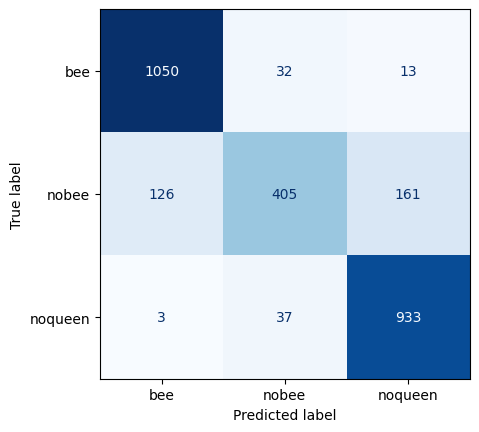

KNN (CQTs features) - Accuracy: 86.52%
Saved: confusion_matrices\KNN_CQTs_features.png


0.8652173913043478

In [177]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(cqts_train_features, cqts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_cqts_knn = knn_classifier.predict(cqts_test_features)
report_confusion(cqts_test_labels, test_accuracy_cqts_knn, "KNN (CQTs features)")

Training time: 0.00 seconds


<Figure size 500x400 with 0 Axes>

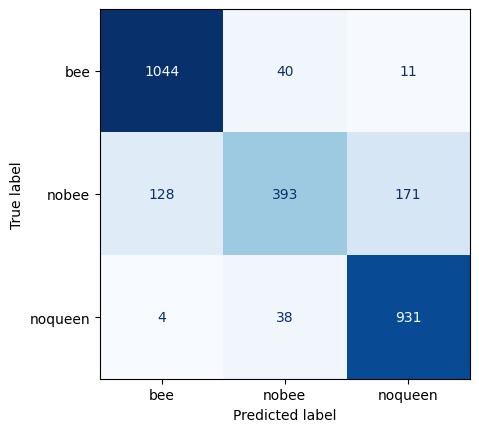

KNN (CQTs features scaled) - Accuracy: 85.80%
Saved: confusion_matrices\KNN_CQTs_features_scaled.png


0.8579710144927536

In [178]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(cqts_train_features_scaled, cqts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_cqts_knn = knn_classifier.predict(cqts_test_features_scaled)
report_confusion(cqts_test_labels, test_accuracy_cqts_knn, "KNN (CQTs features scaled)")

Training time: 2.06 seconds


<Figure size 500x400 with 0 Axes>

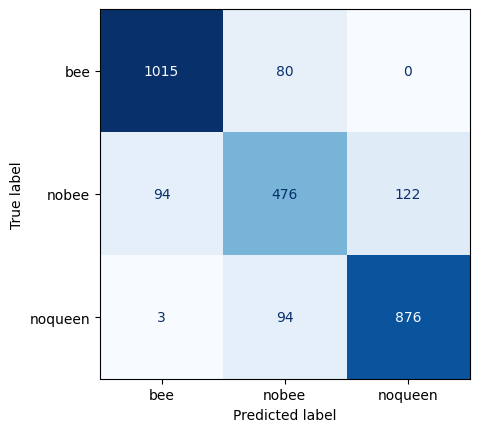

SVM RBF (CQTs features) - Accuracy: 85.76%
Saved: confusion_matrices\SVM_RBF_CQTs_features.png


0.8576086956521739

In [179]:
start_time = time.time()

svm_rbf_classifier = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

svm_rbf_classifier.fit(cqts_train_features, cqts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_svm_rbf = svm_rbf_classifier.predict(cqts_test_features)
report_confusion(cqts_test_labels, test_predictions_svm_rbf, "SVM RBF (CQTs features)")

Training time: 2.20 seconds


<Figure size 500x400 with 0 Axes>

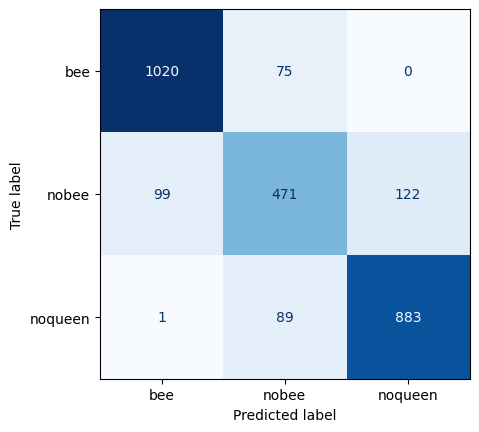

SVM RBF (CQTs features scaled) - Accuracy: 86.01%
Saved: confusion_matrices\SVM_RBF_CQTs_features_scaled.png


0.8601449275362318

In [180]:
start_time = time.time()

svm_rbf_classifier = SVC(C=100, kernel='rbf', degree=3, gamma=0.1, coef0=0.0, shrinking=True, 
                         probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, 
                         max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=42)

svm_rbf_classifier.fit(cqts_train_features_scaled, cqts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_svm_rbf = svm_rbf_classifier.predict(cqts_test_features_scaled)
report_confusion(cqts_test_labels, test_predictions_svm_rbf, "SVM RBF (CQTs features scaled)")

Training time: 8.49 seconds


<Figure size 500x400 with 0 Axes>

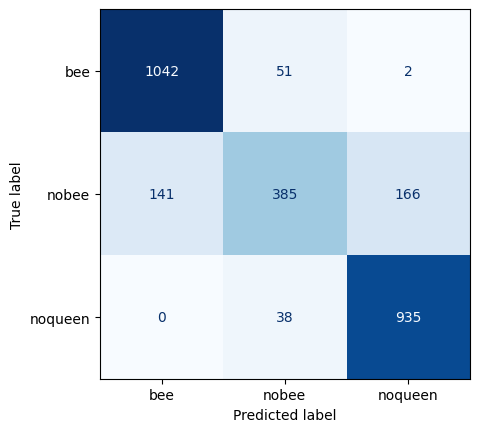

Random Forest (CQTs features) - Accuracy: 85.58%
Saved: confusion_matrices\Random_Forest_CQTs_features.png


0.8557971014492753

In [181]:
start_time = time.time()

rf_classifier = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                       min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                       max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                       n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                       ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier.fit(cqts_train_features, cqts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_accuracy_cqts_rf = rf_classifier.predict(cqts_test_features)
report_confusion(cqts_test_labels, test_accuracy_cqts_rf, "Random Forest (CQTs features)")

Training time: 14.76 seconds


<Figure size 500x400 with 0 Axes>

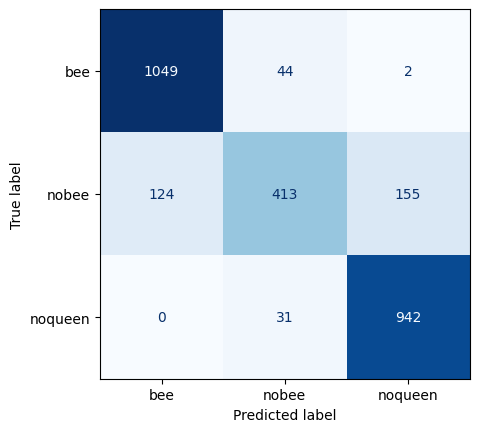

Extra Trees (CQTs features) - Accuracy: 87.10%
Saved: confusion_matrices\Extra_Trees_CQTs_features.png


0.8710144927536232

In [182]:
start_time = time.time()

et_classifier = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

et_classifier.fit(cqts_train_features, cqts_train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

test_predictions_et = et_classifier.predict(cqts_test_features)
report_confusion(cqts_test_labels, test_predictions_et, "Extra Trees (CQTs features)")

# FFTs + CQTs

Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...
Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...
FFTs+CQTs shapes: (11032, 341) (2760, 341)
SVM_RBF (raw) - Train: 3.39s


<Figure size 500x400 with 0 Axes>

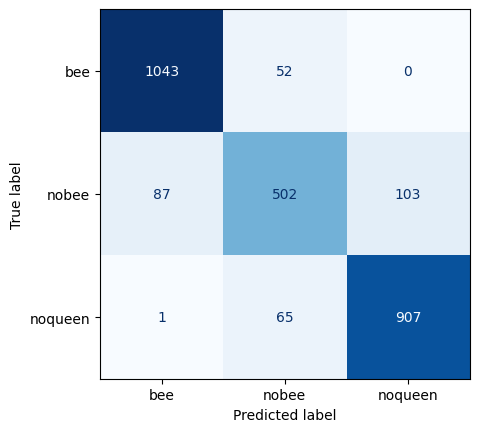

SVM_RBF (FFTs+CQTs raw) - Accuracy: 88.84%
Saved: confusion_matrices\SVM_RBF_FFTsCQTs_raw.png
KNN (raw) - Train: 0.01s


<Figure size 500x400 with 0 Axes>

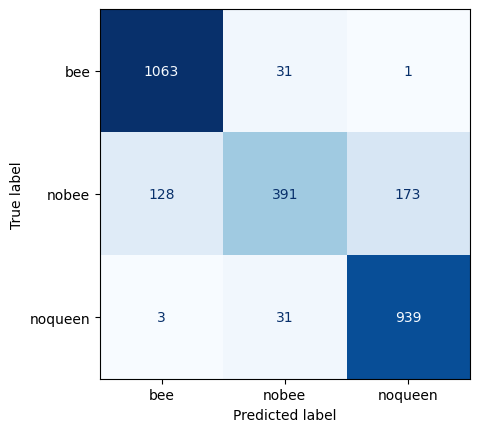

KNN (FFTs+CQTs raw) - Accuracy: 86.70%
Saved: confusion_matrices\KNN_FFTsCQTs_raw.png
RF (raw) - Train: 7.95s


<Figure size 500x400 with 0 Axes>

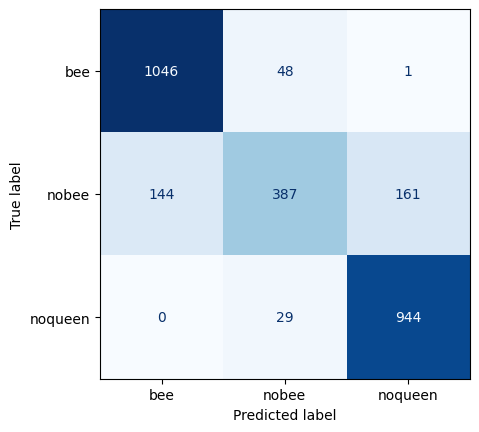

RF (FFTs+CQTs raw) - Accuracy: 86.12%
Saved: confusion_matrices\RF_FFTsCQTs_raw.png
ET (raw) - Train: 2.25s


<Figure size 500x400 with 0 Axes>

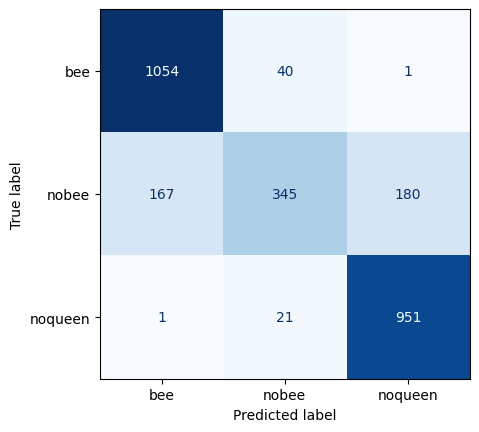

ET (FFTs+CQTs raw) - Accuracy: 85.14%
Saved: confusion_matrices\ET_FFTsCQTs_raw.png
SVM_RBF (scaled) - Train: 3.47s


<Figure size 500x400 with 0 Axes>

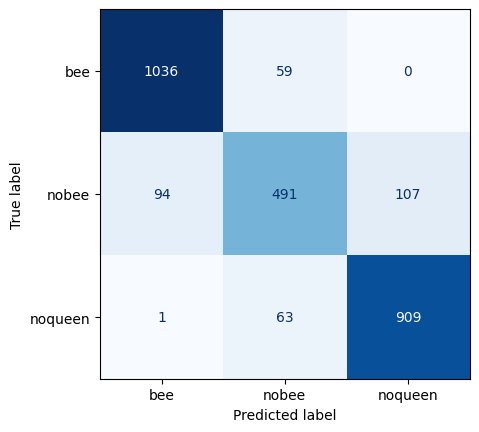

SVM_RBF (FFTs+CQTs scaled) - Accuracy: 88.26%
Saved: confusion_matrices\SVM_RBF_FFTsCQTs_scaled.png
KNN (scaled) - Train: 0.01s


<Figure size 500x400 with 0 Axes>

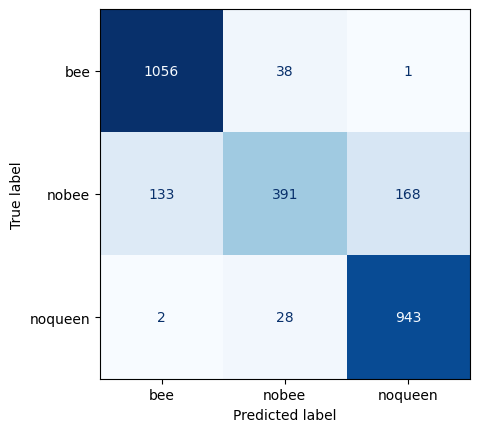

KNN (FFTs+CQTs scaled) - Accuracy: 86.59%
Saved: confusion_matrices\KNN_FFTsCQTs_scaled.png
RF (scaled) - Train: 7.81s


<Figure size 500x400 with 0 Axes>

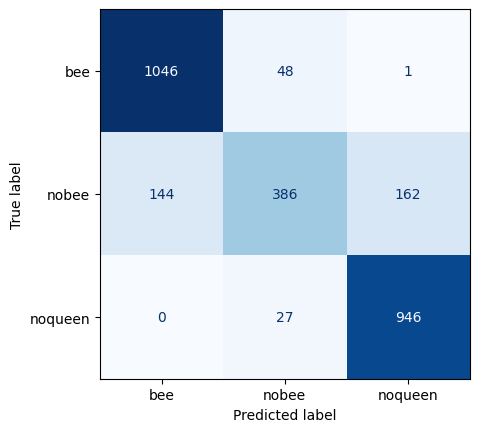

RF (FFTs+CQTs scaled) - Accuracy: 86.16%
Saved: confusion_matrices\RF_FFTsCQTs_scaled.png
ET (scaled) - Train: 2.42s


<Figure size 500x400 with 0 Axes>

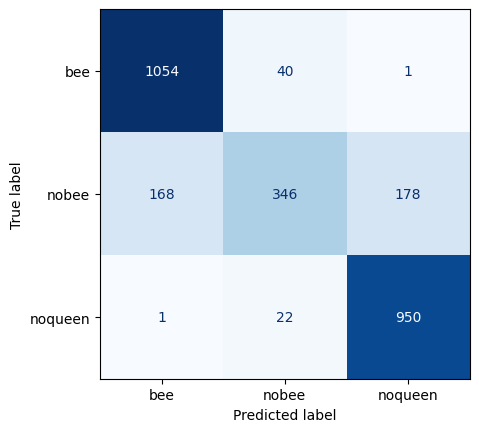

ET (FFTs+CQTs scaled) - Accuracy: 85.14%
Saved: confusion_matrices\ET_FFTsCQTs_scaled.png


In [183]:
# ==== FFTs + CQTs (raw) =====================================================

# 1) Load lại FFTs và CQTs nếu chưa sẵn
train_features_fft, train_labels_fft = load_fft_features_from_directory(
    train_path, sample_rate=22050, NFFT=512, output_dir=output_dir, dataset_type='train'
)
val_features_fft, val_labels_fft = load_fft_features_from_directory(
    val_path, sample_rate=22050, NFFT=512, output_dir=output_dir, dataset_type='val'
)
test_features_fft, test_labels_fft = load_fft_features_from_directory(
    test_path, sample_rate=22050, NFFT=512, output_dir=output_dir, dataset_type='test'
)
train_features_fft = np.vstack((train_features_fft, val_features_fft))
train_labels_fft = np.hstack((train_labels_fft, val_labels_fft))

cqts_train_features, cqts_train_labels = load_cqts_features_from_directory(
    train_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01,
    fmin=None, n_bins=84, bins_per_octave=12, output_dir=output_dir, dataset_type='train'
)
cqts_val_features, cqts_val_labels = load_cqts_features_from_directory(
    val_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01,
    fmin=None, n_bins=84, bins_per_octave=12, output_dir=output_dir, dataset_type='val'
)
cqts_test_features, cqts_test_labels = load_cqts_features_from_directory(
    test_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01,
    fmin=None, n_bins=84, bins_per_octave=12, output_dir=output_dir, dataset_type='test'
)
cqts_train_features = np.vstack((cqts_train_features, cqts_val_features))
cqts_train_labels = np.hstack((cqts_train_labels, cqts_val_labels))

# 2) Kiểm tra label khớp (FFTs & CQTs)
if np.array_equal(train_labels_fft, cqts_train_labels) and np.array_equal(test_labels_fft, cqts_test_labels):
    combined_train_labels_ffts_cqts = train_labels_fft
    combined_test_labels_ffts_cqts  = test_labels_fft
else:
    print("⚠ Labels mismatch: dùng labels từ FFTs.")
    combined_train_labels_ffts_cqts = train_labels_fft
    combined_test_labels_ffts_cqts  = test_labels_fft

# 3) Nối đặc trưng (FFTs + CQTs)
combined_train_features_ffts_cqts = np.hstack((train_features_fft, cqts_train_features))
combined_test_features_ffts_cqts  = np.hstack((test_features_fft, cqts_test_features))
print("FFTs+CQTs shapes:", combined_train_features_ffts_cqts.shape, combined_test_features_ffts_cqts.shape)

# 4) Chuẩn hóa
scaler_ffts_cqts = StandardScaler()
combined_train_features_ffts_cqts_scaled = scaler_ffts_cqts.fit_transform(combined_train_features_ffts_cqts)
combined_test_features_ffts_cqts_scaled  = scaler_ffts_cqts.transform(combined_test_features_ffts_cqts)

# 5) Huấn luyện & đánh giá với tham số như FFTs + CQT
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

models = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', degree=3, gamma=0.03752055855124281,
                   coef0=0.0, shrinking=True, probability=False, tol=0.0005319450186421158,
                   cache_size=500, class_weight=None, verbose=False, max_iter=-1,
                   decision_function_shape='ovr', break_ties=False, random_state=42),
    "KNN": KNeighborsClassifier(
        n_neighbors=7, weights='distance', metric='minkowski', p=2
    ),
    "RF": RandomForestClassifier(
        n_estimators=400, max_depth=None, n_jobs=-1, random_state=42
    ),
    "ET": ExtraTreesClassifier(
        n_estimators=600, max_depth=None, n_jobs=-1, random_state=42
    ),
}

# Raw
for name, clf in models.items():
    t0 = time.time()
    clf.fit(combined_train_features_ffts_cqts, combined_train_labels_ffts_cqts)
    train_dur = time.time()-t0
    y_pred = clf.predict(combined_test_features_ffts_cqts)
    print(f"{name} (raw) - Train: {train_dur:.2f}s")
    report_confusion(combined_test_labels_ffts_cqts, y_pred, f"{name} (FFTs+CQTs raw)")

# Scaled
for name, clf in models.items():
    t0 = time.time()
    clf.fit(combined_train_features_ffts_cqts_scaled, combined_train_labels_ffts_cqts)
    train_dur = time.time()-t0
    y_pred = clf.predict(combined_test_features_ffts_cqts_scaled)
    print(f"{name} (scaled) - Train: {train_dur:.2f}s")
    report_confusion(combined_test_labels_ffts_cqts, y_pred, f"{name} (FFTs+CQTs scaled)")


PCA shapes: (11032, 130) (2760, 130) | (11032, 80) (2760, 80)
PCA+Concat shapes: (11032, 210) (2760, 210)
SVM_RBF (PCA raw) - Train: 2.33s


<Figure size 500x400 with 0 Axes>

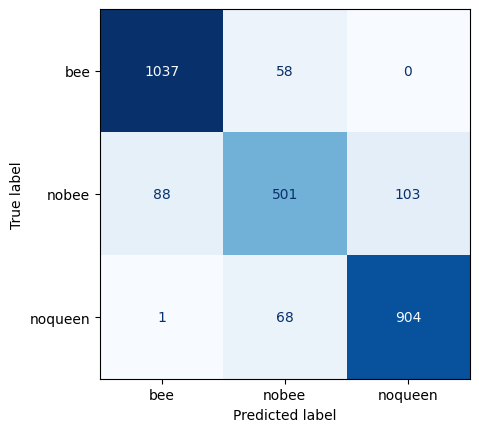

SVM_RBF (PCA FFTs+CQTs raw) - Accuracy: 88.48%
Saved: confusion_matrices\SVM_RBF_PCA_FFTsCQTs_raw.png
KNN (PCA raw) - Train: 0.01s


<Figure size 500x400 with 0 Axes>

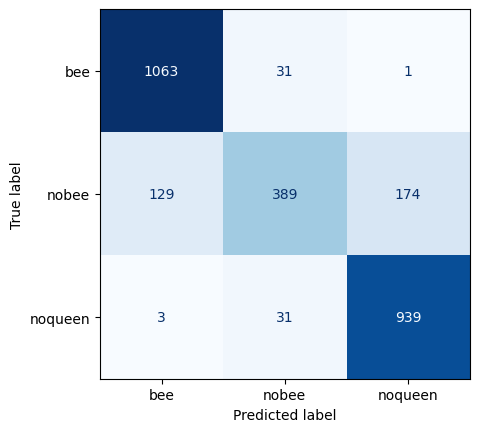

KNN (PCA FFTs+CQTs raw) - Accuracy: 86.63%
Saved: confusion_matrices\KNN_PCA_FFTsCQTs_raw.png
RF (PCA raw) - Train: 6.63s


<Figure size 500x400 with 0 Axes>

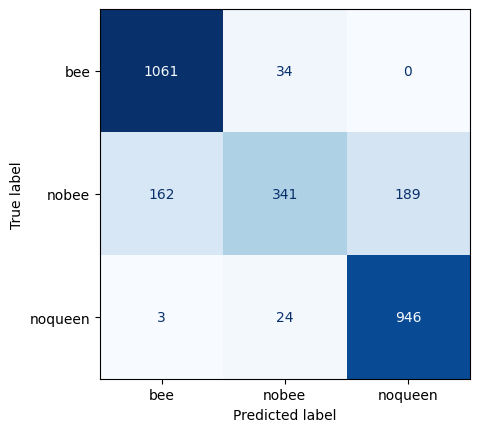

RF (PCA FFTs+CQTs raw) - Accuracy: 85.07%
Saved: confusion_matrices\RF_PCA_FFTsCQTs_raw.png
ET (PCA raw) - Train: 2.10s


<Figure size 500x400 with 0 Axes>

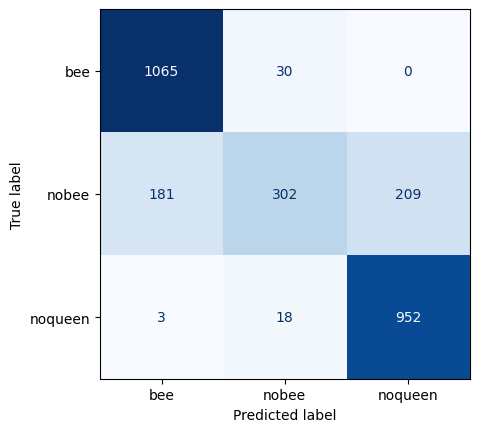

ET (PCA FFTs+CQTs raw) - Accuracy: 84.02%
Saved: confusion_matrices\ET_PCA_FFTsCQTs_raw.png
SVM_RBF (PCA scaled) - Train: 7.74s


<Figure size 500x400 with 0 Axes>

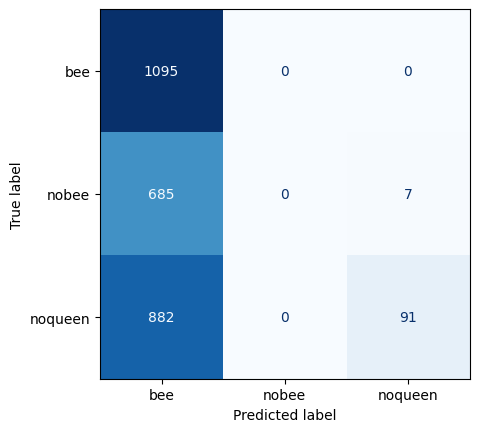

SVM_RBF (PCA FFTs+CQTs scaled) - Accuracy: 42.97%
Saved: confusion_matrices\SVM_RBF_PCA_FFTsCQTs_scaled.png
KNN (PCA scaled) - Train: 0.00s


<Figure size 500x400 with 0 Axes>

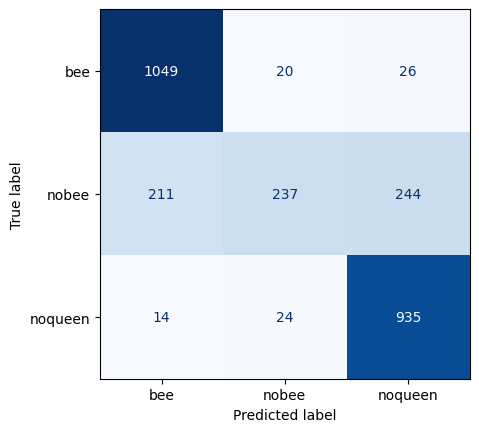

KNN (PCA FFTs+CQTs scaled) - Accuracy: 80.47%
Saved: confusion_matrices\KNN_PCA_FFTsCQTs_scaled.png
RF (PCA scaled) - Train: 6.63s


<Figure size 500x400 with 0 Axes>

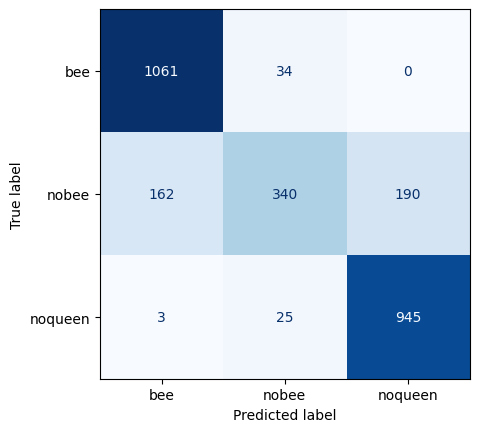

RF (PCA FFTs+CQTs scaled) - Accuracy: 85.00%
Saved: confusion_matrices\RF_PCA_FFTsCQTs_scaled.png
ET (PCA scaled) - Train: 2.23s


<Figure size 500x400 with 0 Axes>

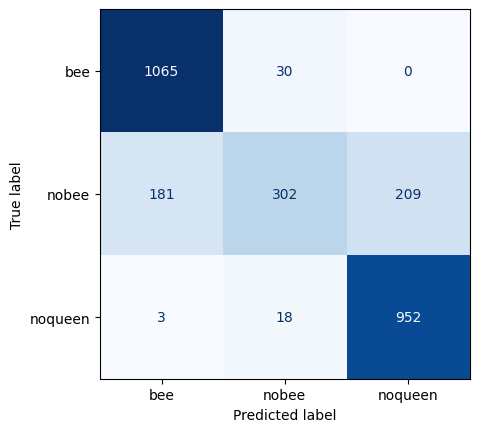

ET (PCA FFTs+CQTs scaled) - Accuracy: 84.02%
Saved: confusion_matrices\ET_PCA_FFTsCQTs_scaled.png


In [184]:
# ==== PCA + FFTs + CQTs =====================================================

from sklearn.decomposition import PCA

def apply_pca_to_features(train_features, test_features, n_components=100):
    pca = PCA(n_components=n_components, random_state=42)
    train_pca = pca.fit_transform(train_features)
    test_pca  = pca.transform(test_features) if test_features is not None else None
    return train_pca, test_pca, pca

# 1) PCA riêng cho FFTs và CQTs
train_ffts_pca, test_ffts_pca, _ = apply_pca_to_features(train_features_fft, test_features_fft, n_components=130)
train_cqts_pca, test_cqts_pca, _ = apply_pca_to_features(cqts_train_features, cqts_test_features, n_components=80)

print("PCA shapes:", train_ffts_pca.shape, test_ffts_pca.shape, "|", train_cqts_pca.shape, test_cqts_pca.shape)

# 2) Concat PCA(FFTs) + PCA(CQTs)
train_features_pca_ffts_cqts = np.hstack((train_ffts_pca, train_cqts_pca))
test_features_pca_ffts_cqts  = np.hstack((test_ffts_pca,  test_cqts_pca))
print("PCA+Concat shapes:", train_features_pca_ffts_cqts.shape, test_features_pca_ffts_cqts.shape)

# 3) Chuẩn hóa
scaler_pca_ffts_cqts = StandardScaler()
train_features_pca_ffts_cqts_scaled = scaler_pca_ffts_cqts.fit_transform(train_features_pca_ffts_cqts)
test_features_pca_ffts_cqts_scaled  = scaler_pca_ffts_cqts.transform(test_features_pca_ffts_cqts)

# 4) Train & Eval với tham số như FFTs + CQT
models = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', degree=3, gamma=0.03752055855124281,
                   coef0=0.0, shrinking=True, probability=False, tol=0.0005319450186421158,
                   cache_size=500, class_weight=None, verbose=False, max_iter=-1,
                   decision_function_shape='ovr', break_ties=False, random_state=42),
    "KNN": KNeighborsClassifier(
        n_neighbors=7, weights='distance', metric='minkowski', p=2
    ),
    "RF": RandomForestClassifier(
        n_estimators=400, max_depth=None, n_jobs=-1, random_state=42
    ),
    "ET": ExtraTreesClassifier(
        n_estimators=600, max_depth=None, n_jobs=-1, random_state=42
    ),
}

# PCA raw
for name, clf in models.items():
    t0 = time.time()
    clf.fit(train_features_pca_ffts_cqts, train_labels_fft)
    train_dur = time.time()-t0
    y_pred = clf.predict(test_features_pca_ffts_cqts)
    print(f"{name} (PCA raw) - Train: {train_dur:.2f}s")
    report_confusion(test_labels_fft, y_pred, f"{name} (PCA FFTs+CQTs raw)")

# PCA scaled
for name, clf in models.items():
    t0 = time.time()
    clf.fit(train_features_pca_ffts_cqts_scaled, train_labels_fft)
    train_dur = time.time()-t0
    y_pred = clf.predict(test_features_pca_ffts_cqts_scaled)
    print(f"{name} (PCA scaled) - Train: {train_dur:.2f}s")
    report_confusion(test_labels_fft, y_pred, f"{name} (PCA FFTs+CQTs scaled)")


# FFTs + CQT + STFT + PCA

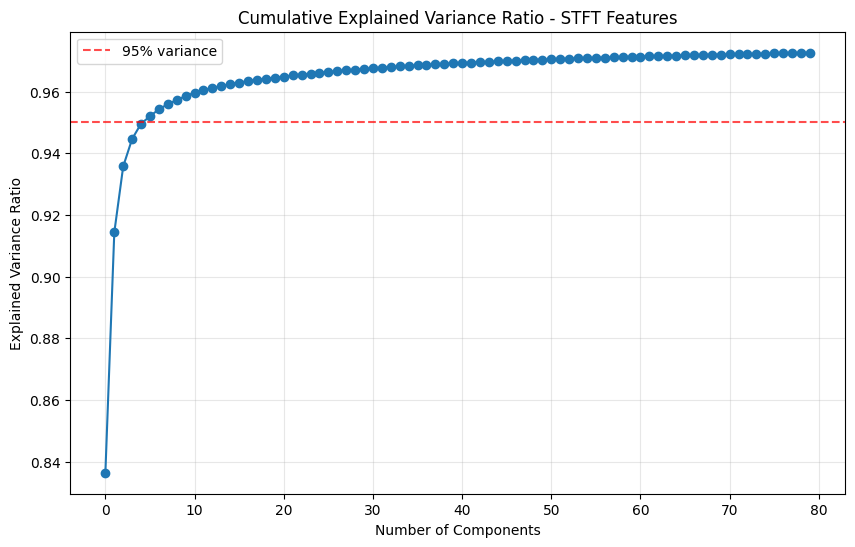

Number of components needed to explain 95% variance: 6
Top 5 principal components explain: 0.9496 of variance
Selected 80 components explain: 0.9726 of variance
Original STFT features shape: (11032, 2049)
PCA STFT features shape: (11032, 80)
Train FFT+CQT features shape: (11032, 246)
Test FFT+CQT features shape: (2760, 246)
Train STFT PCA features shape: (11032, 80)
Test STFT PCA features shape: (2760, 80)
Train labels shape: (11032,)
Test labels shape: (2760,)
STFT train labels shape: (11032,)
STFT test labels shape: (2760,)
✓ Labels are consistent across all feature sets
Final combined features shape - Train: (11032, 326)
Final combined features shape - Test: (2760, 326)
Feature combination completed successfully!


In [185]:
def apply_pca_to_stft(stft_features, test_stft_features=None, n_components=100, plot=True):
    from sklearn.decomposition import PCA
    
    # Khởi tạo và huấn luyện PCA
    pca = PCA(n_components=n_components, random_state=3951)
    train_pca = pca.fit_transform(stft_features)  # Sửa từ train_features_stft
    
    # Áp dụng cho tập kiểm tra (nếu có)
    test_pca = None
    if test_stft_features is not None:
        test_pca = pca.transform(test_stft_features)
    
    # Vẽ đồ thị tỷ lệ phương sai giải thích được
    if plot:
        explained_variance_ratio = pca.explained_variance_ratio_
        cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
        
        plt.figure(figsize=(10, 6))
        plt.plot(cumulative_variance_ratio, marker='o')
        plt.axhline(y=0.95, color='r', linestyle='--', alpha=0.7, label='95% variance')
        plt.grid(True, alpha=0.3)
        plt.title('Cumulative Explained Variance Ratio - STFT Features')
        plt.xlabel('Number of Components')
        plt.ylabel('Explained Variance Ratio')
        plt.legend()
        plt.show()
        
        # Tìm số lượng thành phần cần thiết để giải thích 95% phương sai
        indices_95 = np.where(cumulative_variance_ratio >= 0.95)[0]
        if len(indices_95) > 0:
            n_components_95 = indices_95[0] + 1
            print(f"Number of components needed to explain 95% variance: {n_components_95}")
        
        # Hiển thị top 5 thành phần chính quan trọng nhất
        print(f"Top 5 principal components explain: {np.sum(explained_variance_ratio[:5]):.4f} of variance")
        print(f"Selected {n_components} components explain: {np.sum(explained_variance_ratio[:n_components]):.4f} of variance")
    
    return train_pca, test_pca, pca

# Áp dụng PCA cho STFT features với tên biến đúng
train_stft_pca, test_stft_pca, stft_pca = apply_pca_to_stft(
    train_features_stft, test_stft_features=test_features_stft, n_components=80
)

print(f"Original STFT features shape: {train_features_stft.shape}")
print(f"PCA STFT features shape: {train_stft_pca.shape}")

# Kiểm tra kích thước trước khi kết hợp
print(f"Train FFT+CQT features shape: {train_features.shape}")
print(f"Test FFT+CQT features shape: {test_features.shape}")
print(f"Train STFT PCA features shape: {train_stft_pca.shape}")
print(f"Test STFT PCA features shape: {test_stft_pca.shape}")

# Đảm bảo labels khớp nhau
print(f"Train labels shape: {train_labels.shape}")
print(f"Test labels shape: {test_labels.shape}")
print(f"STFT train labels shape: {train_labels_stft.shape}")
print(f"STFT test labels shape: {test_labels_stft.shape}")

# Kiểm tra labels có giống nhau không
if np.array_equal(train_labels, train_labels_stft) and np.array_equal(test_labels, test_labels_stft):
    print("✓ Labels are consistent across all feature sets")
else:
    print("⚠ Warning: Labels are not consistent across feature sets")

# Kết hợp các đặc trưng
combined_train_features = np.hstack((train_features, train_stft_pca))
combined_test_features = np.hstack((test_features, test_stft_pca))

print(f"Final combined features shape - Train: {combined_train_features.shape}")
print(f"Final combined features shape - Test: {combined_test_features.shape}")

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
train_features_scaled = scaler.fit_transform(combined_train_features)
test_features_scaled = scaler.transform(combined_test_features)

print("Feature combination completed successfully!")

In [186]:
print(train_features.shape, test_features.shape)
print(train_stft_pca.shape, test_stft_pca.shape)

(11032, 246) (2760, 246)
(11032, 80) (2760, 80)


In [187]:
combined_train_features = np.hstack((train_features, train_stft_pca))
combined_test_features = np.hstack((test_features, test_stft_pca))

In [188]:
combined_train_features.shape

(11032, 326)

In [189]:
scaler = StandardScaler()
train_features_scaled = scaler.fit_transform(combined_train_features)
test_features_scaled  = scaler.transform(combined_test_features)

Training time: 0.01 seconds


<Figure size 500x400 with 0 Axes>

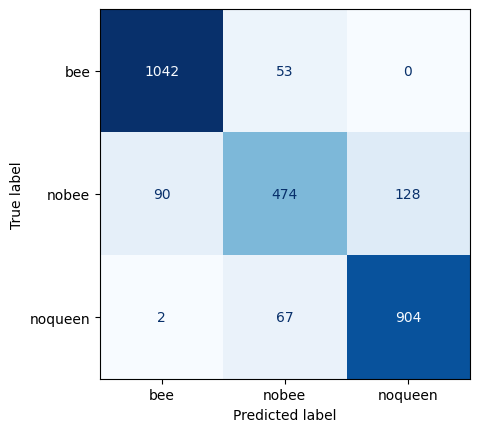

KNN (Combined PCA features) - Accuracy: 87.68%
Saved: confusion_matrices\KNN_Combined_PCA_features.png


0.8768115942028986

In [190]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=1)
knn_classifier.fit(combined_train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Evaluate on test set
test_accuracy_knn = knn_classifier.predict(combined_test_features)
report_confusion(test_labels, test_accuracy_knn, "KNN (Combined PCA features)")


Training time: 0.01 seconds


<Figure size 500x400 with 0 Axes>

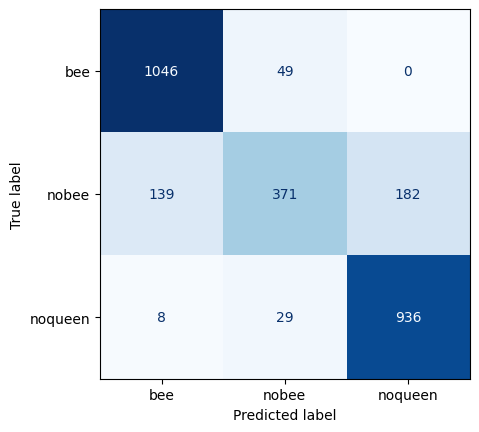

KNN (Combined PCA features scaled) - Accuracy: 85.25%
Saved: confusion_matrices\KNN_Combined_PCA_features_scaled.png


0.8525362318840579

In [191]:
start_time = time.time()

knn_classifier = KNeighborsClassifier(n_neighbors=3)
knn_classifier.fit(train_features_scaled, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Evaluate on test set (scaled)
test_accuracy_knn = knn_classifier.predict(test_features_scaled)
report_confusion(test_labels, test_accuracy_knn, "KNN (Combined PCA features scaled)")


Training time: 7.29 seconds


<Figure size 500x400 with 0 Axes>

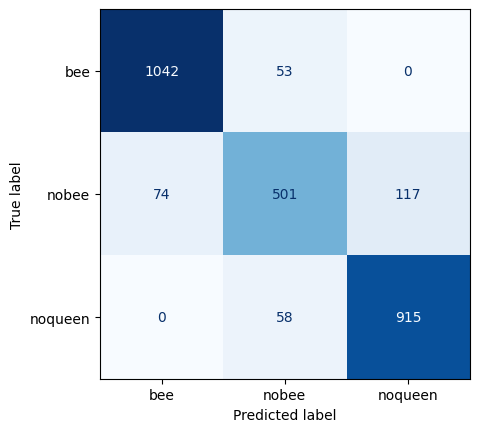

SVM RBF (Combined PCA features) - Accuracy: 89.06%
Saved: confusion_matrices\SVM_RBF_Combined_PCA_features.png


0.8905797101449275

In [192]:
start_time = time.time()

svm_rbf_classifier = SVC(C=71.19418600172986, kernel='rbf', degree=3, gamma=0.03752055855124281, 
                         coef0=0.0, shrinking=True, probability=False, tol=0.0005319450186421158, 
                         cache_size=500, class_weight=None, verbose=False, max_iter=-1, 
                         decision_function_shape='ovr', break_ties=False, random_state=42)


# Huấn luyện mô hình SVM trên dữ liệu kết hợp
svm_rbf_classifier.fit(combined_train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_svm_rbf = svm_rbf_classifier.predict(combined_test_features)
report_confusion(test_labels, test_predictions_svm_rbf, "SVM RBF (Combined PCA features)")


Training time: 18.87 seconds


<Figure size 500x400 with 0 Axes>

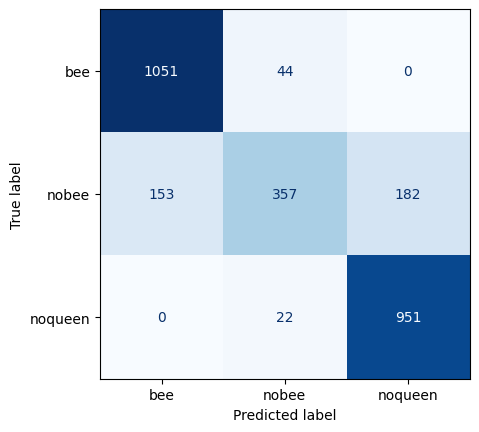

Random Forest (Combined PCA features) - Accuracy: 85.47%
Saved: confusion_matrices\Random_Forest_Combined_PCA_features.png


0.8547101449275363

In [193]:
start_time = time.time()

rf_classifier = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2, 
                                       min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
                                       max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, 
                                       n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None, 
                                       ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

rf_classifier.fit(combined_train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Evaluate on test set
test_accuracy_rf = rf_classifier.predict(combined_test_features)
report_confusion(test_labels, test_accuracy_rf, "Random Forest (Combined PCA features)")


Training time: 60.16 seconds


<Figure size 500x400 with 0 Axes>

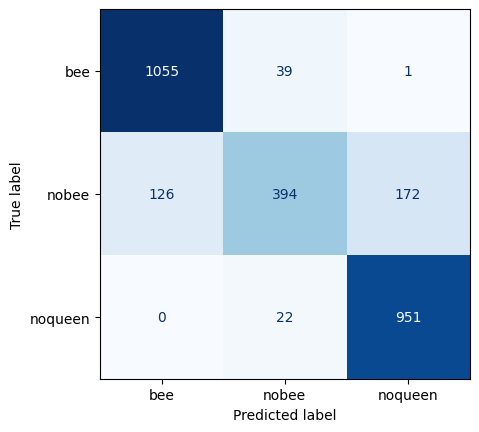

Extra Trees (Combined PCA features) - Accuracy: 86.96%
Saved: confusion_matrices\Extra_Trees_Combined_PCA_features.png


0.8695652173913043

In [194]:
start_time = time.time()

et_classifier = ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2, min_samples_leaf=1, 
                                     min_weight_fraction_leaf=0.0, max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.0,
                                     bootstrap=False, oob_score=False, n_jobs=None, random_state=42, verbose=0, warm_start=False, 
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

et_classifier.fit(combined_train_features, train_labels)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

# Đánh giá mô hình trên bộ testing
test_predictions_et = et_classifier.predict(combined_test_features)
report_confusion(test_labels, test_predictions_et, "Extra Trees (Combined PCA features)")


# PCA (FFTs + CQTs + STFT)

In [195]:
# ============================================================================
# KẾT HỢP FFTs + CQTs + STFT VÀ TRAIN SVM VỚI THAM SỐ TỐI ƯU
# ============================================================================

import numpy as np
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

# 1. LOAD FFTs FEATURES
print("=" * 60)
print("Loading FFTs features...")
train_features_fft, train_labels_fft = load_fft_features_from_directory(
    train_path, sample_rate=22050, NFFT=512, 
    output_dir=output_dir, dataset_type='train'
)
val_features_fft, val_labels_fft = load_fft_features_from_directory(
    val_path, sample_rate=22050, NFFT=512, 
    output_dir=output_dir, dataset_type='val'
)
test_features_fft, test_labels_fft = load_fft_features_from_directory(
    test_path, sample_rate=22050, NFFT=512, 
    output_dir=output_dir, dataset_type='test'
)

train_features_fft = np.vstack((train_features_fft, val_features_fft))
train_labels_fft = np.hstack((train_labels_fft, val_labels_fft))
print(f"FFTs - Train shape: {train_features_fft.shape}, Test shape: {test_features_fft.shape}")

# 2. LOAD CQTs FEATURES
print("=" * 60)
print("Loading CQTs features...")
cqts_train_features, cqts_train_labels = load_cqts_features_from_directory(
    train_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01, 
    fmin=None, n_bins=84, bins_per_octave=12, 
    output_dir=output_dir, dataset_type='train'
)
cqts_val_features, cqts_val_labels = load_cqts_features_from_directory(
    val_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01, 
    fmin=None, n_bins=84, bins_per_octave=12, 
    output_dir=output_dir, dataset_type='val'
)
cqts_test_features, cqts_test_labels = load_cqts_features_from_directory(
    test_path, sample_rate=22050, frame_size=0.025, frame_stride=0.01, 
    fmin=None, n_bins=84, bins_per_octave=12, 
    output_dir=output_dir, dataset_type='test'
)

cqts_train_features = np.vstack((cqts_train_features, cqts_val_features))
cqts_train_labels = np.hstack((cqts_train_labels, cqts_val_labels))
print(f"CQTs - Train shape: {cqts_train_features.shape}, Test shape: {cqts_test_features.shape}")

# 3. LOAD STFT FEATURES
print("=" * 60)
print("Loading STFT features...")
stft_train_features, stft_train_labels = load_stft_features_from_directory(
    train_path, sample_rate=22050, n_fft=4096, hop_length=1024, 
    output_dir=output_dir, dataset_type='train'
)
stft_val_features, stft_val_labels = load_stft_features_from_directory(
    val_path, sample_rate=22050, n_fft=4096, hop_length=1024, 
    output_dir=output_dir, dataset_type='val'
)
stft_test_features, stft_test_labels = load_stft_features_from_directory(
    test_path, sample_rate=22050, n_fft=4096, hop_length=1024, 
    output_dir=output_dir, dataset_type='test'
)

stft_train_features = np.vstack((stft_train_features, stft_val_features))
stft_train_labels = np.hstack((stft_train_labels, stft_val_labels))
print(f"STFT - Train shape: {stft_train_features.shape}, Test shape: {stft_test_features.shape}")

# 4. ÁP DỤNG PCA CHO MỖI LOẠI FEATURES
print("=" * 60)
print("Applying PCA...")

def apply_pca_to_features(train_features, test_features, n_components=100, plot=False):
    """Áp dụng PCA để giảm số chiều của features."""
    from sklearn.decomposition import PCA
    import matplotlib.pyplot as plt
    
    pca = PCA(n_components=n_components)
    train_pca = pca.fit_transform(train_features)
    
    if test_features is not None:
        test_pca = pca.transform(test_features)
    else:
        test_pca = None
    
    # Hiển thị thông tin về PCA nếu cần
    if plot:
        explained_variance_ratio = pca.explained_variance_ratio_
        cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
        
        plt.figure(figsize=(10, 6))
        plt.plot(cumulative_variance_ratio, marker='o')
        plt.axhline(y=0.95, color='r', linestyle='-')
        plt.grid(True)
        plt.title('Cumulative Explained Variance Ratio')
        plt.xlabel('Number of Components')
        plt.ylabel('Explained Variance Ratio')
        plt.show()
        
        n_components_95 = np.where(cumulative_variance_ratio >= 0.95)[0][0] + 1
        print(f"Number of components needed to explain 95% variance: {n_components_95}")
    
    return train_pca, test_pca, pca

# PCA cho FFTs: 130 components (giống như FFT ban đầu cho 99.38%)
train_ffts_pca, test_ffts_pca, fft_pca = apply_pca_to_features(
    train_features_fft, test_features_fft, n_components=130, plot=False
)
print(f"FFTs PCA - Train shape: {train_ffts_pca.shape}, Test shape: {test_ffts_pca.shape}")

# PCA cho CQTs: 80 components (giống như CQT ban đầu)
train_cqts_pca, test_cqts_pca, cqts_pca = apply_pca_to_features(
    cqts_train_features, cqts_test_features, n_components=80, plot=False
)
print(f"CQTs PCA - Train shape: {train_cqts_pca.shape}, Test shape: {test_cqts_pca.shape}")

# PCA cho STFT: 80 components (giống như STFT ban đầu)
train_stft_pca, test_stft_pca, stft_pca = apply_pca_to_features(
    stft_train_features, stft_test_features, n_components=80, plot=False
)
print(f"STFT PCA - Train shape: {train_stft_pca.shape}, Test shape: {test_stft_pca.shape}")

# 5. KẾT HỢP TẤT CẢ FEATURES
print("=" * 60)
print("Combining features...")

# Kết hợp FFTs + CQTs
train_features_combined = np.hstack((train_ffts_pca, train_cqts_pca))
test_features_combined = np.hstack((test_ffts_pca, test_cqts_pca))

# Kết hợp thêm STFT
combined_train_features = np.hstack((train_features_combined, train_stft_pca))
combined_test_features = np.hstack((test_features_combined, test_stft_pca))

print(f"Combined features - Train shape: {combined_train_features.shape}")
print(f"Combined features - Test shape: {combined_test_features.shape}")

# 6. TRAIN VỚI CÁC MÔ HÌNH: KNN, SVM (RBF), RF, ET
print("=" * 60)
print("Training and evaluating multiple models...")

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

models = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', degree=3, gamma=0.03752055855124281, 
                         coef0=0.0, shrinking=True, probability=False, tol=0.0005319450186421158, 
                         cache_size=500, class_weight=None, verbose=False, max_iter=-1, 
                         decision_function_shape='ovr', break_ties=False, random_state=42),
    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights='distance',
        metric='minkowski',
        p=2  # Euclidean
    ),
    "RF": RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        n_jobs=-1,
        random_state=42
    ),
    "ET": ExtraTreesClassifier(
        n_estimators=600,
        max_depth=None,
        n_jobs=-1,
        random_state=42
    ),
}

results = {}
timings = {}

for name, clf in models.items():
    print("-" * 60)
    print(f"Training {name}...")
    start_time = time.time()
    clf.fit(combined_train_features, train_labels_fft)
    train_time = time.time() - start_time

    print(f"Evaluating {name}...")
    y_pred = clf.predict(combined_test_features)
    acc = accuracy_score(test_labels_fft, y_pred)

    results[name] = acc
    timings[name] = train_time

    print(f"{name} - Test Accuracy: {acc * 100:.2f}% | Training time: {train_time:.2f}s")

print("=" * 60)
print("Leaderboard (sorted by accuracy):")
for name, acc in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f"{name}: {acc * 100:.2f}% (train {timings[name]:.2f}s)")
print("=" * 60)

Loading FFTs features...
Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...
FFTs - Train shape: (11032, 257), Test shape: (2760, 257)
Loading CQTs features...
Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...
CQTs - Train shape: (11032, 84), Test shape: (2760, 84)
Loading STFT features...
Loading train data from .pkl files...
Loading val data from .pkl files...
Loading test data from .pkl files...
STFT - Train shape: (11032, 2049), Test shape: (2760, 2049)
Applying PCA...
FFTs PCA - Train shape: (11032, 130), Test shape: (2760, 130)
CQTs PCA - Train shape: (11032, 80), Test shape: (2760, 80)
STFT PCA - Train shape: (11032, 80), Test shape: (2760, 80)
Combining features...
Combined features - Train shape: (11032, 290)
Combined features - Test shape: (2760, 290)
Training and evaluating multiple models...
------------------------------------------------------------
Trai

Combining FFTs + CQTs + STFT for Dataset 2...
Combined features shape (train): (11032, 2390)
Combined features shape (test): (2760, 2390)

--------------------------------------------------
Training on NON-SCALED (Raw) Data
--------------------------------------------------

---> Training KNN on raw FFTs+CQTs+STFT (D2)...
Training time: 0.03 seconds


<Figure size 500x400 with 0 Axes>

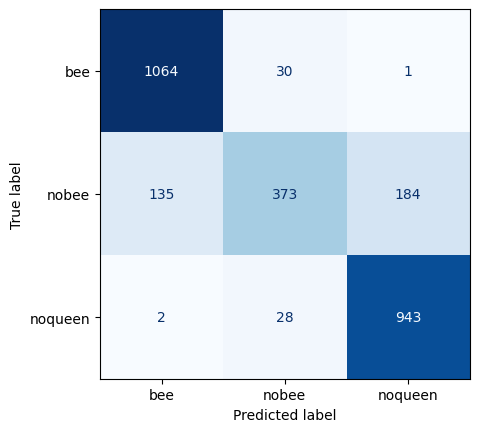

KNN - D2 FFTs+CQTs+STFT (Raw) - Accuracy: 86.23%
Saved: confusion_matrices\KNN_-_D2_FFTsCQTsSTFT_Raw.png

---> Training SVM on raw FFTs+CQTs+STFT (D2)...
Training time: 124.46 seconds


<Figure size 500x400 with 0 Axes>

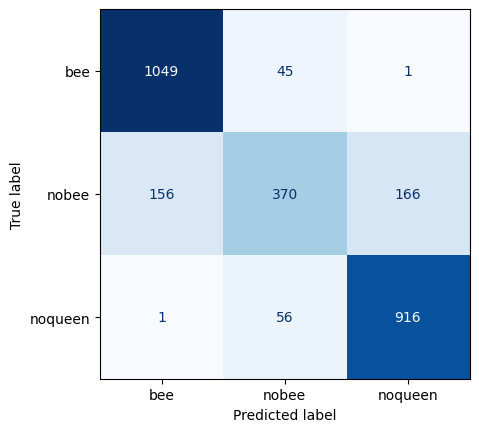

SVM - D2 FFTs+CQTs+STFT (Raw) - Accuracy: 84.60%
Saved: confusion_matrices\SVM_-_D2_FFTsCQTsSTFT_Raw.png

---> Training RF on raw FFTs+CQTs+STFT (D2)...
Training time: 23.07 seconds


<Figure size 500x400 with 0 Axes>

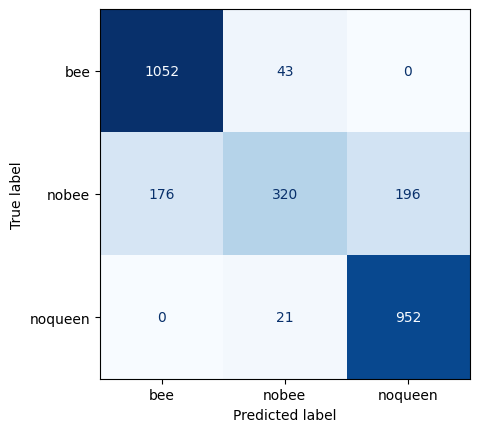

RF - D2 FFTs+CQTs+STFT (Raw) - Accuracy: 84.20%
Saved: confusion_matrices\RF_-_D2_FFTsCQTsSTFT_Raw.png

---> Training ET on raw FFTs+CQTs+STFT (D2)...
Training time: 7.99 seconds


<Figure size 500x400 with 0 Axes>

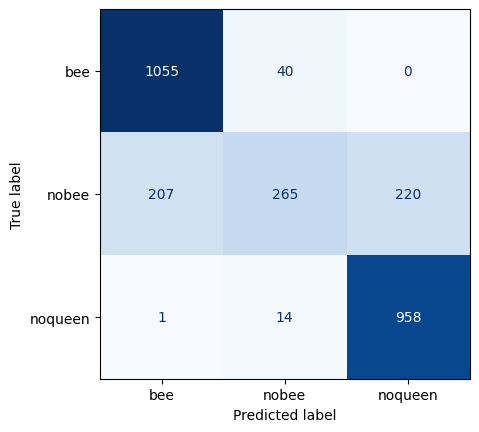

ET - D2 FFTs+CQTs+STFT (Raw) - Accuracy: 82.54%
Saved: confusion_matrices\ET_-_D2_FFTsCQTsSTFT_Raw.png

Applying StandardScaler...
Scaling training data finished in 0.21 seconds.
Scaling test data finished in 0.02 seconds.

--------------------------------------------------
Training on SCALED Data
--------------------------------------------------

---> Training KNN on scaled FFTs+CQTs+STFT (D2)...
Training time: 0.03 seconds


<Figure size 500x400 with 0 Axes>

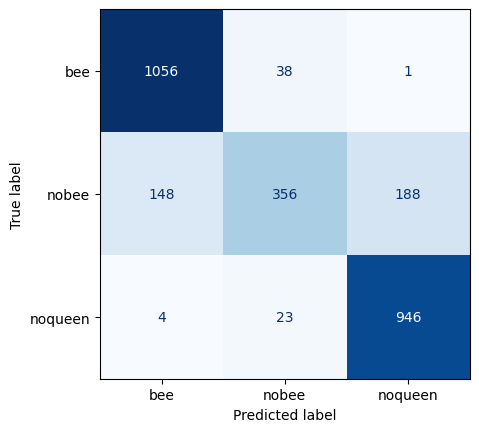

KNN - D2 FFTs+CQTs+STFT (Scaled) - Accuracy: 85.43%
Saved: confusion_matrices\KNN_-_D2_FFTsCQTsSTFT_Scaled.png

---> Training SVM on scaled FFTs+CQTs+STFT (D2)...
Training time: 113.02 seconds


<Figure size 500x400 with 0 Axes>

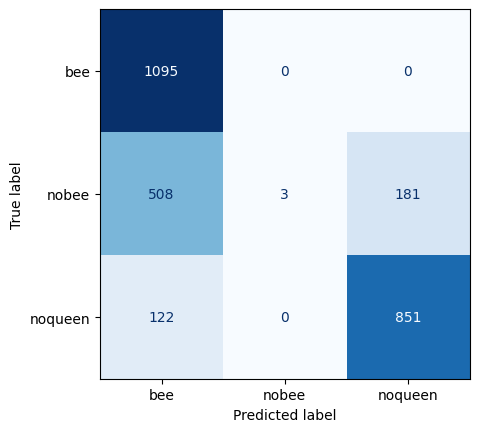

SVM - D2 FFTs+CQTs+STFT (Scaled) - Accuracy: 70.62%
Saved: confusion_matrices\SVM_-_D2_FFTsCQTsSTFT_Scaled.png

---> Training RF on scaled FFTs+CQTs+STFT (D2)...
Training time: 22.87 seconds


<Figure size 500x400 with 0 Axes>

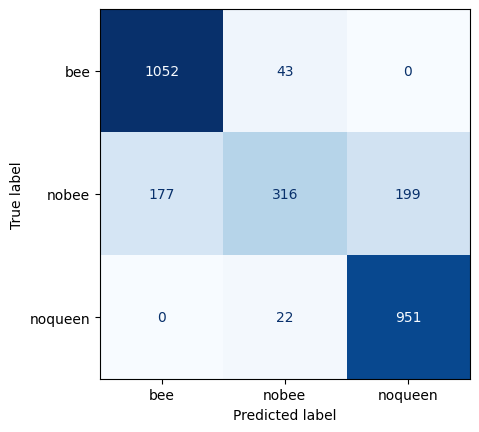

RF - D2 FFTs+CQTs+STFT (Scaled) - Accuracy: 84.02%
Saved: confusion_matrices\RF_-_D2_FFTsCQTsSTFT_Scaled.png

---> Training ET on scaled FFTs+CQTs+STFT (D2)...
Training time: 7.86 seconds


<Figure size 500x400 with 0 Axes>

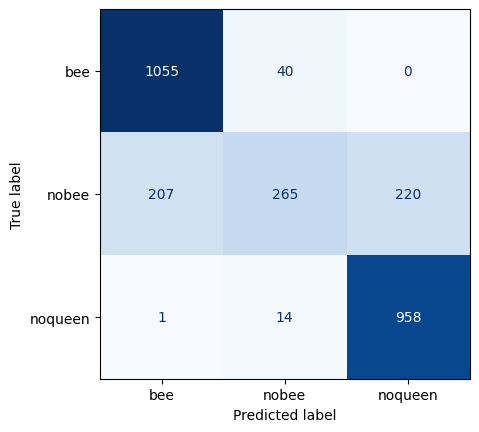

ET - D2 FFTs+CQTs+STFT (Scaled) - Accuracy: 82.54%
Saved: confusion_matrices\ET_-_D2_FFTsCQTsSTFT_Scaled.png


In [196]:
# ============================================================================
# DATASET 2: Huấn luyện 'FFTs + CQTs + STFT' (Raw và Scaled)
# ============================================================================
import numpy as np
import time
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score

# --- Giả định các biến của Dataset 2 đã tồn tại từ các cell trước ---
# train_features_fft, test_features_fft
# cqts_train_features, cqts_test_features
# train_features_stft, test_features_stft
# train_labels_fft, test_labels_fft
# -------------------------------------------------------------------

print("="*60)
print("Combining FFTs + CQTs + STFT for Dataset 2...")
print("="*60)

try:
    # 1. Kết hợp các biến đã có (từ các cell của Dataset 2)
    combined_train_D2_A = np.hstack((
        train_features_fft,  # (11032, 257)
        cqts_train_features, # (11032, 84)
        train_features_stft  # (11032, 2049)
    ))
    
    combined_test_D2_A = np.hstack((
        test_features_fft,   # (2760, 257)
        cqts_test_features,  # (2760, 84)
        test_features_stft   # (2760, 2049)
    ))

    # Tổng features: 257 + 84 + 2049 = 2390
    print(f"Combined features shape (train): {combined_train_D2_A.shape}")
    print(f"Combined features shape (test): {combined_test_D2_A.shape}")

    # 2. Định nghĩa các models (Dùng các models/params từ D2 Cell 118)
    models_d2 = {
        "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', p=2),
        "SVM": SVC(C=71.194, kernel='rbf', gamma=0.0375, random_state=42, cache_size=500),
        "RF": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42),
        "ET": ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42)
    }

    # ==================================
    # 3. Huấn luyện trên dữ liệu GỐC (Non-scaled)
    # ==================================
    print("\n" + "-" * 50)
    print("Training on NON-SCALED (Raw) Data")
    print("-" * 50)

    for name, clf in models_d2.items():
        print(f"\n---> Training {name} on raw FFTs+CQTs+STFT (D2)...")
        start_time = time.time()
        clf.fit(combined_train_D2_A, train_labels_fft) # Dùng nhãn chung
        print(f"Training time: {time.time() - start_time:.2f} seconds")
        
        test_predictions = clf.predict(combined_test_D2_A)
        report_confusion(test_labels_fft, test_predictions, f"{name} - D2 FFTs+CQTs+STFT (Raw)")

    # ==================================
    # 4. Chuẩn hóa dữ liệu với StandardScaler
    # ==================================
    print("\n" + "="*60)
    print("Applying StandardScaler...")
    print("="*60)
    
    scaler = StandardScaler()
    
    # Fit scaler trên dữ liệu huấn luyện và transform nó
    start_time = time.time()
    scaled_train_D2_A = scaler.fit_transform(combined_train_D2_A)
    print(f"Scaling training data finished in {time.time() - start_time:.2f} seconds.")

    # Chỉ transform dữ liệu test (dùng scaler đã học từ data train)
    start_time = time.time()
    scaled_test_D2_A = scaler.transform(combined_test_D2_A)
    print(f"Scaling test data finished in {time.time() - start_time:.2f} seconds.")

    # ==================================
    # 5. Huấn luyện trên dữ liệu ĐÃ CHUẨN HÓA (Scaled)
    # ==================================
    print("\n" + "-" * 50)
    print("Training on SCALED Data")
    print("-" * 50)

    for name, clf in models_d2.items():
        print(f"\n---> Training {name} on scaled FFTs+CQTs+STFT (D2)...")
        start_time = time.time()
        clf.fit(scaled_train_D2_A, train_labels_fft)
        print(f"Training time: {time.time() - start_time:.2f} seconds")
        
        test_predictions_scaled = clf.predict(scaled_test_D2_A)
        report_confusion(test_labels_fft, test_predictions_scaled, f"{name} - D2 FFTs+CQTs+STFT (Scaled)")

except NameError as e:
    print(f"Lỗi: {e}. Đảm bảo các biến đặc trưng và nhãn của Dataset 2 đã được tải và có tên chính xác.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Combining FFTs + CQT + STFT (raw, non-PCA) for Dataset 2...
Combined features shape (train): (11032, 2390)
Combined features shape (test): (2760, 2390)

--------------------------------------------------
Training on NON-SCALED (Raw) Data
--------------------------------------------------

---> Training KNN on raw FFTs+CQT+STFT (D2)...
Training time: 0.03 seconds


<Figure size 500x400 with 0 Axes>

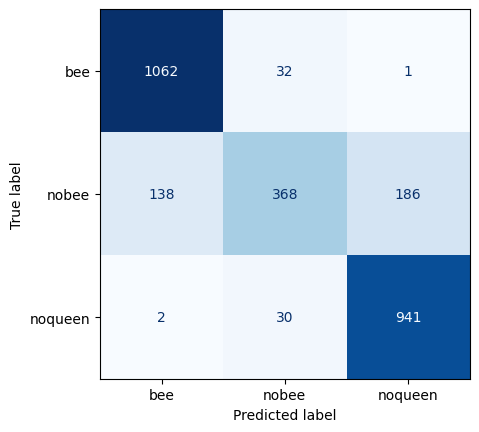

KNN - D2 FFTs+CQT+STFT (Raw) - Accuracy: 85.91%
Saved: confusion_matrices\KNN_-_D2_FFTsCQTSTFT_Raw.png

---> Training SVM on raw FFTs+CQT+STFT (D2)...
Training time: 124.14 seconds


<Figure size 500x400 with 0 Axes>

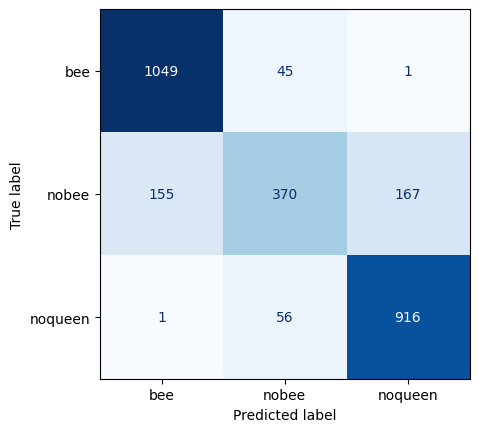

SVM - D2 FFTs+CQT+STFT (Raw) - Accuracy: 84.60%
Saved: confusion_matrices\SVM_-_D2_FFTsCQTSTFT_Raw.png

---> Training RF on raw FFTs+CQT+STFT (D2)...
Training time: 23.38 seconds


<Figure size 500x400 with 0 Axes>

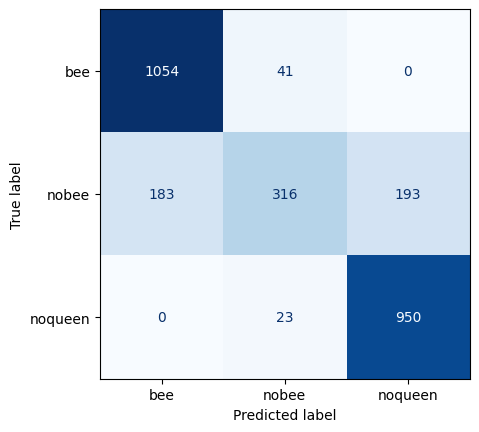

RF - D2 FFTs+CQT+STFT (Raw) - Accuracy: 84.06%
Saved: confusion_matrices\RF_-_D2_FFTsCQTSTFT_Raw.png

---> Training ET on raw FFTs+CQT+STFT (D2)...
Training time: 7.79 seconds


<Figure size 500x400 with 0 Axes>

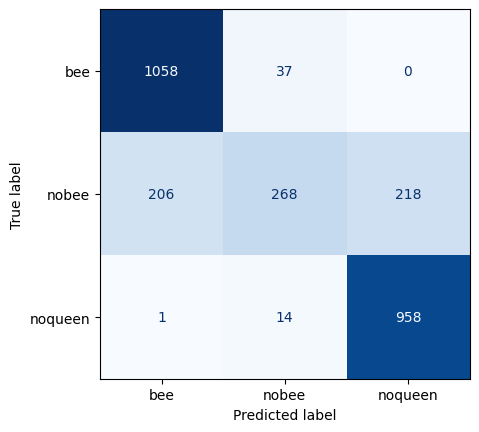

ET - D2 FFTs+CQT+STFT (Raw) - Accuracy: 82.75%
Saved: confusion_matrices\ET_-_D2_FFTsCQTSTFT_Raw.png

Applying StandardScaler...
Scaling training data finished in 0.22 seconds.
Scaling test data finished in 0.02 seconds.

--------------------------------------------------
Training on SCALED Data
--------------------------------------------------

---> Training KNN on scaled FFTs+CQT+STFT (D2)...
Training time: 0.03 seconds


<Figure size 500x400 with 0 Axes>

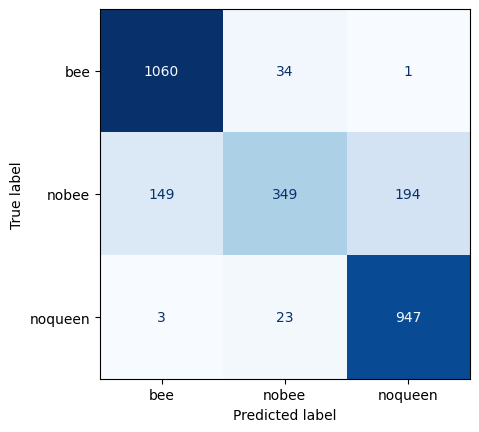

KNN - D2 FFTs+CQT+STFT (Scaled) - Accuracy: 85.36%
Saved: confusion_matrices\KNN_-_D2_FFTsCQTSTFT_Scaled.png

---> Training SVM on scaled FFTs+CQT+STFT (D2)...
Training time: 113.28 seconds


<Figure size 500x400 with 0 Axes>

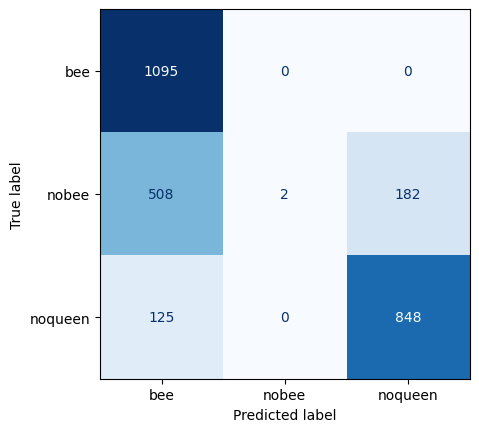

SVM - D2 FFTs+CQT+STFT (Scaled) - Accuracy: 70.47%
Saved: confusion_matrices\SVM_-_D2_FFTsCQTSTFT_Scaled.png

---> Training RF on scaled FFTs+CQT+STFT (D2)...
Training time: 23.06 seconds


<Figure size 500x400 with 0 Axes>

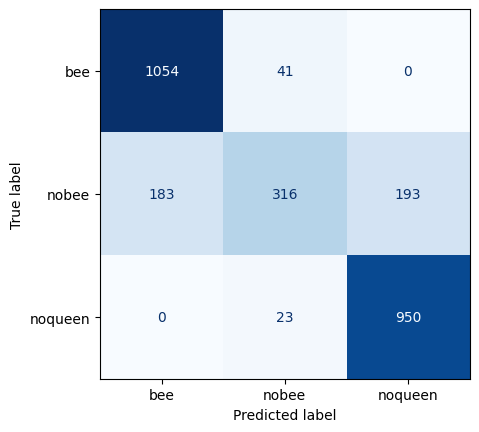

RF - D2 FFTs+CQT+STFT (Scaled) - Accuracy: 84.06%
Saved: confusion_matrices\RF_-_D2_FFTsCQTSTFT_Scaled.png

---> Training ET on scaled FFTs+CQT+STFT (D2)...
Training time: 7.75 seconds


<Figure size 500x400 with 0 Axes>

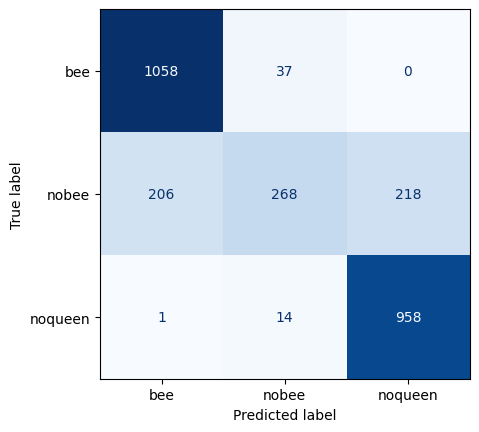

ET - D2 FFTs+CQT+STFT (Scaled) - Accuracy: 82.75%
Saved: confusion_matrices\ET_-_D2_FFTsCQTSTFT_Scaled.png


In [197]:
# ============================================================================
# DATASET 2: Huấn luyện 'FFTs + CQT + STFT' (Raw, Non-PCA, Scaled)
# ============================================================================
import numpy as np
import time
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score

# --- Giả định các biến của Dataset 2 đã tồn tại từ các cell trước ---
# train_features_fft, test_features_fft
# train_features_cqt, test_features_cqt
# train_features_stft, test_features_stft
# train_labels_fft, test_labels_fft (nhãn chung)
# -------------------------------------------------------------------

print("="*60)
print("Combining FFTs + CQT + STFT (raw, non-PCA) for Dataset 2...")
print("="*60)

try:
    # 1. Kết hợp các biến đã có (từ các cell của Dataset 2)
    combined_train_D2_C = np.hstack((
        train_features_fft,  # (11032, 257)
        train_features_cqt,  # (11032, 84)
        train_features_stft  # (11032, 2049)
    ))
    
    combined_test_D2_C = np.hstack((
        test_features_fft,   # (2760, 257)
        test_features_cqt,   # (2760, 84)
        test_features_stft   # (2760, 2049)
    ))

    # Tổng features: 257 + 84 + 2049 = 2390
    print(f"Combined features shape (train): {combined_train_D2_C.shape}")
    print(f"Combined features shape (test): {combined_test_D2_C.shape}")

    # 2. Định nghĩa các models (Dùng các models/params từ D2 Cell 118)
    models_d2 = {
        "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', p=2),
        "SVM": SVC(C=71.194, kernel='rbf', gamma=0.0375, random_state=42, cache_size=500),
        "RF": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42),
        "ET": ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42)
    }

    # ==================================
    # 3. Huấn luyện trên dữ liệu GỐC (Non-scaled)
    # ==================================
    print("\n" + "-" * 50)
    print("Training on NON-SCALED (Raw) Data")
    print("-" * 50)

    for name, clf in models_d2.items():
        print(f"\n---> Training {name} on raw FFTs+CQT+STFT (D2)...")
        start_time = time.time()
        clf.fit(combined_train_D2_C, train_labels_fft)
        print(f"Training time: {time.time() - start_time:.2f} seconds")
        
        test_predictions = clf.predict(combined_test_D2_C)
        report_confusion(test_labels_fft, test_predictions, f"{name} - D2 FFTs+CQT+STFT (Raw)")

    # ==================================
    # 4. Chuẩn hóa dữ liệu với StandardScaler
    # ==================================
    print("\n" + "="*60)
    print("Applying StandardScaler...")
    print("="*60)
    
    scaler = StandardScaler()
    
    # Fit scaler trên dữ liệu huấn luyện và transform nó
    start_time = time.time()
    scaled_train_D2_C = scaler.fit_transform(combined_train_D2_C)
    print(f"Scaling training data finished in {time.time() - start_time:.2f} seconds.")

    # Chỉ transform dữ liệu test (dùng scaler đã học từ data train)
    start_time = time.time()
    scaled_test_D2_C = scaler.transform(combined_test_D2_C)
    print(f"Scaling test data finished in {time.time() - start_time:.2f} seconds.")

    # ==================================
    # 5. Huấn luyện trên dữ liệu ĐÃ CHUẨN HÓA (Scaled)
    # ==================================
    print("\n" + "-" * 50)
    print("Training on SCALED Data")
    print("-" * 50)

    for name, clf in models_d2.items():
        print(f"\n---> Training {name} on scaled FFTs+CQT+STFT (D2)...")
        start_time = time.time()
        clf.fit(scaled_train_D2_C, train_labels_fft)
        print(f"Training time: {time.time() - start_time:.2f} seconds")
        
        test_predictions_scaled = clf.predict(scaled_test_D2_C)
        report_confusion(test_labels_fft, test_predictions_scaled, f"{name} - D2 FFTs+CQT+STFT (Scaled)")

except NameError as e:
    print(f"Lỗi: {e}. Đảm bảo các biến 'train_features_fft', 'train_features_cqt', 'train_features_stft' của Dataset 2 đã được tải.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")